# TOP

In [1]:
# Load Installed Packages
import xarray as xr
import numpy as np
import pandas as pd
import xesmf as xe
import xcdat as xc
from matplotlib import pyplot as plt
from matplotlib.gridspec import GridSpec
import matplotlib.ticker as mticker
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from eofs.standard import Eof

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from scipy.signal import firwin
from scipy.signal import detrend

In [2]:
input_filepath = "../data/"
index_filepath = "../data/ref_index/"
output_filepath = "../created/"

# INDEX CONFIGURATION
Set `INDEX_NAME` below, then Run All. Everything downstream reads from this.

In [3]:
# ── INDEX CONFIGURATION ───────────────────────────────────────────────
# SST-based:        ENSO, PDO, AMO, IOD, TPI
# Atmosphere-based: AO, AAO, SAM, NAO, NPI

INDEX_NAME = "PDO"

INDEX_CONFIG = {
    # ── SST-based ──────────────────────────────
    "ENSO": dict(group="SST", pos_label="El Niño", neg_label="La Niña",
                 ylim=(-2.75, 2.75),
                 ref_file="sst.index.ref.nc", ref_var="enso"),
    "PDO":  dict(group="SST", pos_label="Positive Phase", neg_label="Negative Phase", ylim=None),
    "AMO":  dict(group="SST", pos_label="Positive Phase", neg_label="Negative Phase", ylim=None),
    "IOD":  dict(group="SST", pos_label="Positive Phase", neg_label="Negative Phase", ylim=None),
    "TPI":  dict(group="SST", pos_label="Positive Phase", neg_label="Negative Phase", ylim=None),
    # ── Atmosphere-based ────────────────────────
    "AO":   dict(group="ATM", pos_label="Positive Phase", neg_label="Negative Phase", ylim=None),
    "AAO":  dict(group="ATM", pos_label="Positive Phase", neg_label="Negative Phase", ylim=None),
    "SAM":  dict(group="ATM", pos_label="Positive Phase", neg_label="Negative Phase", ylim=None),
    "NAO":  dict(group="ATM", pos_label="Positive Phase", neg_label="Negative Phase", ylim=None),
    "NPI":  dict(group="ATM", pos_label="Positive Phase", neg_label="Negative Phase", ylim=None),
}

_cfg      = INDEX_CONFIG[INDEX_NAME]
POS_LABEL = _cfg["pos_label"]        # used in figure titles / phase labels
NEG_LABEL = _cfg["neg_label"]
TS_YLIM   = _cfg.get("ylim")         # fixed y-range for tercile time series (None = autoscale)
REF_FILE  = _cfg.get("ref_file")     # reference series exists only for some indices
REF_VAR   = _cfg.get("ref_var")

# Index time-series files by group (each file holds one variable per index,
# named to match INDEX_NAME). Update the ATM paths if yours are named differently.
if _cfg["group"] == "SST":
    VAL_FILE, LT_FILE, ST_FILE = "SST_INDEX_VAL.nc", "SST_INDEX_LT.nc", "SST_INDEX_ST.nc"
else:
    VAL_FILE, LT_FILE, ST_FILE = "ATM_INDEX_VAL.nc", "ATM_INDEX_LT.nc", "ATM_INDEX_ST.nc"

print(f"Configured for {INDEX_NAME} ({_cfg['group']}-based) | +: {POS_LABEL} | -: {NEG_LABEL}")


Configured for PDO (SST-based) | +: Positive Phase | -: Negative Phase


In [4]:
# Load Utils
%load_ext autoreload
%autoreload 2

import os, sys
sys.path.insert(0, os.path.abspath("../utils"))

# Load Local Utils
import utils_plotting_index
import utils_plotting_map
import utils_general
import utils_regression
import utils_agreement

In [5]:
utils_agreement.INDEX_NAME = INDEX_NAME
utils_agreement.POS_LABEL  = POS_LABEL
utils_agreement.NEG_LABEL  = NEG_LABEL

In [6]:
import warnings
warnings.filterwarnings("ignore", message="Degrees of freedom <= 0")

In [7]:
import matplotlib.colors as mcolors

OrBu = mcolors.LinearSegmentedColormap.from_list(
    "OrBu", ["#cc6600", "#ffffff", "#006bb3"], N=10
)

# LOAD ALL 

## TIME SERIES

In [8]:
# Index time series -- variable name inside each file matches INDEX_NAME
IDX_VAL = xr.open_dataset(output_filepath + VAL_FILE)[INDEX_NAME]
IDX_LT  = xr.open_dataset(output_filepath + LT_FILE)[INDEX_NAME]
IDX_ST  = xr.open_dataset(output_filepath + ST_FILE)[INDEX_NAME]

# Reference series (only defined for some indices, e.g. ENSO)
IDX_REF = xr.open_dataset(output_filepath + REF_FILE)[REF_VAR] if REF_FILE else None

In [9]:
IDX_VAL_dt = utils_general.detrend_da(IDX_VAL)
IDX_LT_dt  = utils_general.detrend_da(IDX_LT)
IDX_ST_dt  = utils_general.detrend_da(IDX_ST)
IDX_REF_dt = utils_general.detrend_da(IDX_REF) if IDX_REF is not None else None

In [10]:
da_seasonal_lt = xr.open_dataset(output_filepath + 'da_seasonal_lt.nc')
da_seasonal_lt

<xarray.Dataset> Size: 8kB
Dimensions:                        (time: 492)
Coordinates:
  * time                           (time) datetime64[ns] 4kB 1901-12-01 ... 2...
Data variables:
    __xarray_dataarray_variable__  (time) datetime64[ns] 4kB ...
Attributes:
    __xarray_dataarray_name__:  time

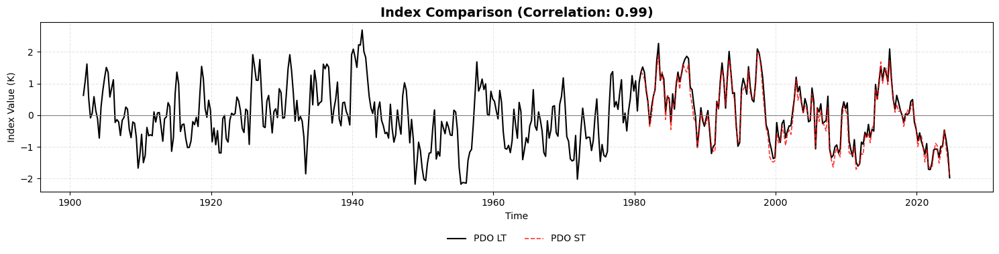

In [11]:
idx_INDEX_TS_LT_ST = utils_plotting_index.index_corr_plot(IDX_LT, IDX_ST, 
                                     label1=f"{INDEX_NAME} LT", label2=f"{INDEX_NAME} ST", 
                                     title="Index Comparison",
                    save_path=f"../figures/{INDEX_NAME}/{INDEX_NAME}_INDEX_TS_LT_ST.png")

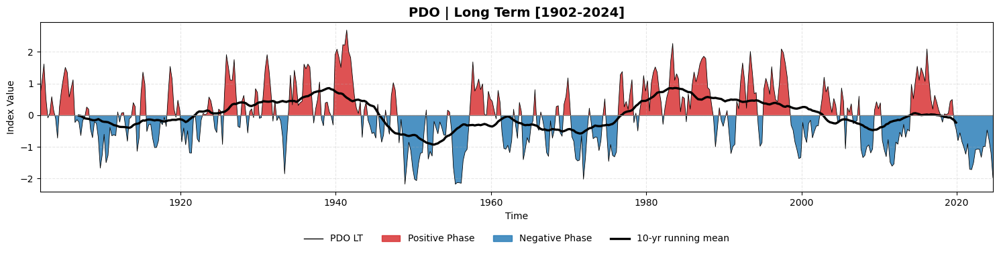

In [12]:
idx_INDEX_TS_LT = utils_plotting_index.index_plot(
    IDX_LT, label=f"{INDEX_NAME} LT",
    title=f"{INDEX_NAME} | Long Term [1902-2024]",
    pos_label=POS_LABEL, neg_label=NEG_LABEL,
    running_mean_years=10,
    save_path=f"../figures/{INDEX_NAME}/{INDEX_NAME}_INDEX_TS_LT.png",
)

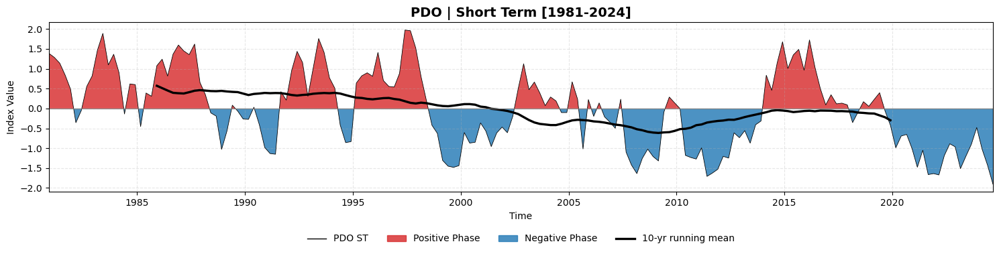

In [13]:
idx_INDEX_TS_ST = utils_plotting_index.index_plot(
    IDX_ST, label=f"{INDEX_NAME} ST",
    title=f"{INDEX_NAME} | Short Term [1981-2024]",
    pos_label=POS_LABEL, neg_label=NEG_LABEL,
    running_mean_years=10,
    save_path=f"../figures/{INDEX_NAME}/{INDEX_NAME}_INDEX_TS_ST.png",
)

## LONG TERM

In [14]:
SST_LT = xr.open_dataset(output_filepath + 'HYDRO_ANOM/SST_ANOM_LT.nc').sst#.groupby('time.season')
PDSI_LT = xr.open_dataset(output_filepath + 'HYDRO_ANOM/PDSI_LT.nc').scpdsi#.groupby('time.season')
TMP_LT = xr.open_dataset(output_filepath + 'HYDRO_ANOM/TMP_ANOM_LT.nc').tmp#.groupby('time.season')
PPT_LT = xr.open_dataset(output_filepath + 'HYDRO_ANOM/PPT_CRU_PCT_ANOM_LT.nc').pre#.groupby('time.season')

In [15]:
SST_LT_dt = utils_general.detrend_da(SST_LT)
PDSI_LT_dt = utils_general.detrend_da(PDSI_LT)
TMP_LT_dt = utils_general.detrend_da(TMP_LT)
PPT_LT_dt = utils_general.detrend_da(PPT_LT)

In [16]:
years_1902_2024 = np.arange(1902, 2025, 1)
years_1902_2024

array([1902, 1903, 1904, 1905, 1906, 1907, 1908, 1909, 1910, 1911, 1912,
       1913, 1914, 1915, 1916, 1917, 1918, 1919, 1920, 1921, 1922, 1923,
       1924, 1925, 1926, 1927, 1928, 1929, 1930, 1931, 1932, 1933, 1934,
       1935, 1936, 1937, 1938, 1939, 1940, 1941, 1942, 1943, 1944, 1945,
       1946, 1947, 1948, 1949, 1950, 1951, 1952, 1953, 1954, 1955, 1956,
       1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967,
       1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978,
       1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989,
       1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000,
       2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011,
       2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022,
       2023, 2024])

## SHORT TERM

In [17]:
SST_ST = xr.open_dataset(output_filepath + 'HYDRO_ANOM/SST_ANOM_ST.nc').sst#.groupby('time.season')
PDSI_ST = xr.open_dataset(output_filepath + 'HYDRO_ANOM/PDSI_ST.nc').scpdsi#.groupby('time.season')
SM_ST = xr.open_dataset(output_filepath + 'HYDRO_ANOM/SM_PCT_ANOM_ST.nc').SMrz#.groupby('time.season')
TMP_ST = xr.open_dataset(output_filepath + 'HYDRO_ANOM/TMP_ANOM_ST.nc').tmp#.groupby('time.season')
PPT_CRU_ST = xr.open_dataset(output_filepath + 'HYDRO_ANOM/PPT_CRU_PCT_ANOM_ST.nc').pre#.groupby('time.season')
PPT_GPCC_ST = xr.open_dataset(output_filepath + 'HYDRO_ANOM/PPT_GPCC_PCT_ANOM_ST.nc').p.sel(time=slice('1981-12-01', '2024-11-01'))#.groupby('time.season')

In [18]:
# Detrend individually
SST_ST_dt    = utils_general.detrend_da(SST_ST)
PDSI_ST_dt   = utils_general.detrend_da(PDSI_ST)
SM_ST_dt     = utils_general.detrend_da(SM_ST)
TMP_ST_dt    = utils_general.detrend_da(TMP_ST)
PPT_CRU_ST_dt  = utils_general.detrend_da(PPT_CRU_ST)
PPT_GPCC_ST_dt = utils_general.detrend_da(PPT_GPCC_ST)

In [19]:
years_1981_2024 = np.arange(1981, 2025, 1)
years_1981_2024

array([1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991,
       1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002,
       2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013,
       2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024])

### PPT GPCP

In [20]:
PPT_GPCP_ST = xr.open_dataset(output_filepath + 'HYDRO_ANOM/PPT_GPCP_PCT_ALL_ANOM_ST_v2.nc').precip#.sel(time=slice('1981-12-01', '2024-11-01'))#.groupby('time.season')
PPT_GPCP_ST

<xarray.DataArray 'precip' (time: 176, lat: 72, lon: 144)> Size: 7MB
[1824768 values with dtype=float32]
Coordinates:
  * lat      (lat) float32 288B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
  * lon      (lon) float32 576B 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
  * time     (time) datetime64[ns] 1kB 1980-12-01 1981-03-01 ... 2024-09-01

In [21]:
PPT_GPCP_ST_dt = utils_general.detrend_da(PPT_GPCP_ST)

In [22]:
#gpcp_land_mask =  xr.open_dataset(input_filepath + "TRMM_all_masks.nc")#, decode_times=False)#.sel(time =slice('1980-12-01', '2024-11-30'))
gpcp_land_mask =  xr.open_dataset(output_filepath + 'GPCP_LAND_MASK.nc')
gpcp_land_mask

<xarray.Dataset> Size: 136kB
Dimensions:          (lat: 72, lon: 144)
Coordinates:
  * lat              (lat) float32 288B -88.75 -86.25 -83.75 ... 86.25 88.75
  * lon              (lon) float32 576B 1.25 3.75 6.25 ... 353.8 356.2 358.8
Data variables:
    landseamask_raw  (lat, lon) float32 41kB ...
    landseamask      (lat, lon) int8 10kB ...
    land_mask        (lat, lon) float32 41kB ...
    sea_mask         (lat, lon) float32 41kB ...
Attributes:
    regrid_method:  bilinear

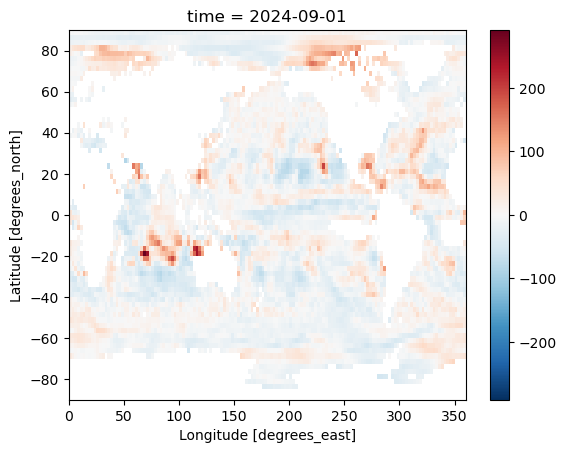

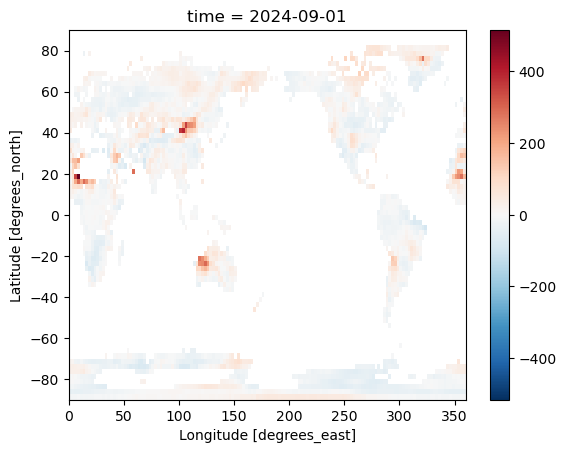

In [23]:
PPT_GPCP_ST_SEA_dt = PPT_GPCP_ST_dt * gpcp_land_mask.land_mask
PPT_GPCP_ST_SEA_dt.isel(time = -1).plot()
plt.show()

PPT_GPCP_ST_LAND_dt = PPT_GPCP_ST_dt * gpcp_land_mask.sea_mask
PPT_GPCP_ST_LAND_dt.isel(time = -1).plot()
plt.show()

# LONG TERM REGRESSIONS [DT]

## PDSI

Saved PDO_SST_PDSI_REG_LT.png


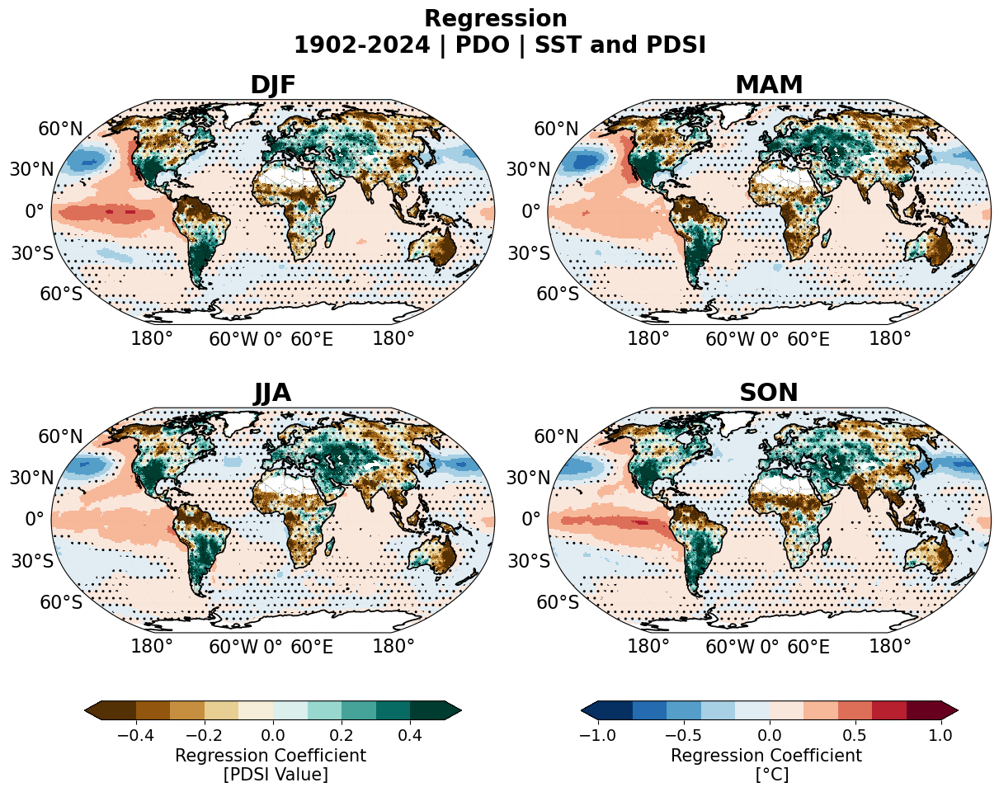

Saved ../nc_files/PDO/PDO_SST_PDSI_REG_LT.nc


In [24]:
idx_reg_pdsi_sst_lt = utils_regression.compute_and_plot_reg_with_corrs_p_MOV(
    idx_values = IDX_LT_dt.groupby('time.season'),
    pdsi_anoms_seasonal = PDSI_LT_dt.groupby('time.season'),
    sst_anoms_seasonal = SST_LT_dt.groupby('time.season'),
    years = years_1902_2024,
    seasons=['DJF','MAM','JJA','SON'], thresh = 0.05,
    cmap_pdsi='BrBG', vlim_pdsi=0.5,
    cmap_sst='RdBu_r', vlim_sst= 1,
    var1_name="PDSI", # <-- new
    var2_name="SST", # <-- new
    period = "LT",# <-- new
    overall_title=f'Regression \n 1902-2024 | {INDEX_NAME} | SST and PDSI ',
    coeff_label1='Regression Coefficient \n [PDSI Value]',
    coeff_label2='Regression Coefficient \n [°C]',
    index_name = INDEX_NAME,
    nc_name ="SST_PDSI",# <-- new
    save_dir=f'../figures/{INDEX_NAME}/',
    nc_dir=f'../nc_files/{INDEX_NAME}/',# <-- new
)

## PPT_CRU

Saved PDO_SST_PPT_CRU_REG_LT.png


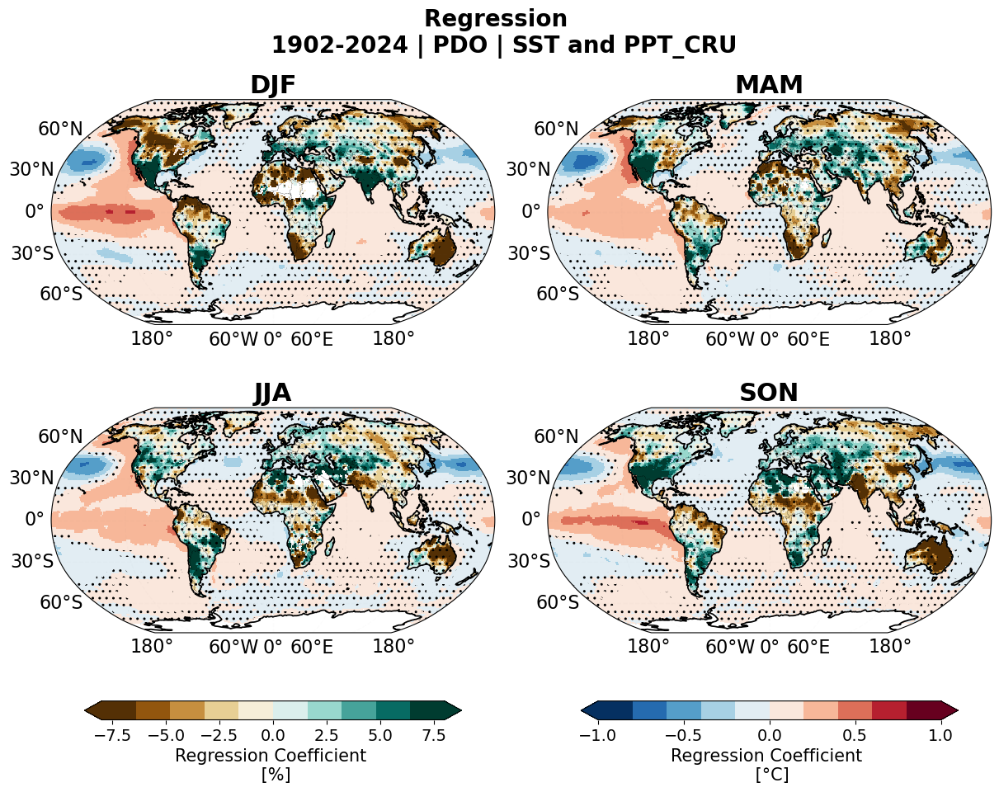

Saved ../nc_files/PDO/PDO_SST_PPT_CRU_REG_LT.nc


In [25]:
# Regression with Detrended Percentage Anomalies
idx_reg_ppt_sst_lt = utils_regression.compute_and_plot_reg_with_corrs_p_MOV(
    idx_values = IDX_LT_dt.groupby('time.season'),
    pdsi_anoms_seasonal = PPT_LT_dt.groupby('time.season'),
    sst_anoms_seasonal = SST_LT_dt.groupby('time.season'),
    years = years_1902_2024,
    seasons=['DJF','MAM','JJA','SON'], thresh = 0.05,
    cmap_pdsi='BrBG', vlim_pdsi=8,
    cmap_sst='RdBu_r', vlim_sst= 1,
    var1_name="PPT_CRU", # <-- new
    var2_name="SST", # <-- new
    period = "LT",# <-- new
    overall_title=f'Regression \n 1902-2024 | {INDEX_NAME} | SST and PPT_CRU',
    coeff_label1='Regression Coefficient \n [%]',
    coeff_label2='Regression Coefficient \n [°C]',
    index_name=f'{INDEX_NAME}',        # <-- new
    nc_name ="SST_PPT_CRU",# <-- new
    save_dir=f'../figures/{INDEX_NAME}/',        
    nc_dir=f'../nc_files/{INDEX_NAME}/',# <-- new

)

## TMP

Saved PDO_SST_TMP_REG_LT.png


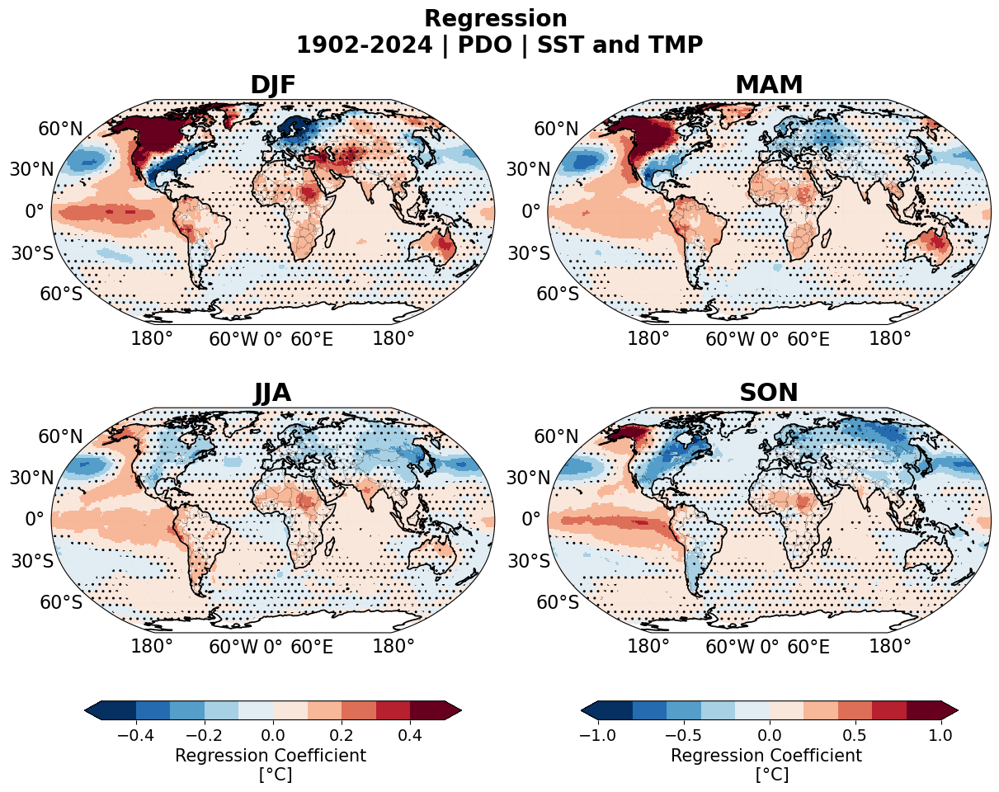

Saved ../nc_files/PDO/PDO_SST_TMP_REG_LT.nc


In [26]:
# Regression Percentage Anomalies
idx_reg_tmp_sst_lt = utils_regression.compute_and_plot_reg_with_corrs_p_MOV(
    idx_values = IDX_LT_dt.groupby('time.season'),
    pdsi_anoms_seasonal = TMP_LT_dt.groupby('time.season'),
    sst_anoms_seasonal = SST_LT_dt.groupby('time.season'),
    years = years_1902_2024,
    seasons=['DJF','MAM','JJA','SON'], thresh = 0.05,
    cmap_pdsi='RdBu_r', vlim_pdsi=0.5,
    cmap_sst='RdBu_r', vlim_sst= 1.0,
    var1_name="TMP", # <-- new
    var2_name="SST", # <-- new
    period = "LT",# <-- new
    overall_title=f'Regression \n 1902-2024 | {INDEX_NAME} | SST and TMP ',
    coeff_label1='Regression Coefficient \n [°C]',
    coeff_label2='Regression Coefficient \n [°C]',
    index_name=f'{INDEX_NAME}',       
    nc_name ="SST_TMP",# <-- new
    save_dir=f'../figures/{INDEX_NAME}/',    # <-- new     
    nc_dir=f'../nc_files/{INDEX_NAME}/',# <-- new

)

## All LT

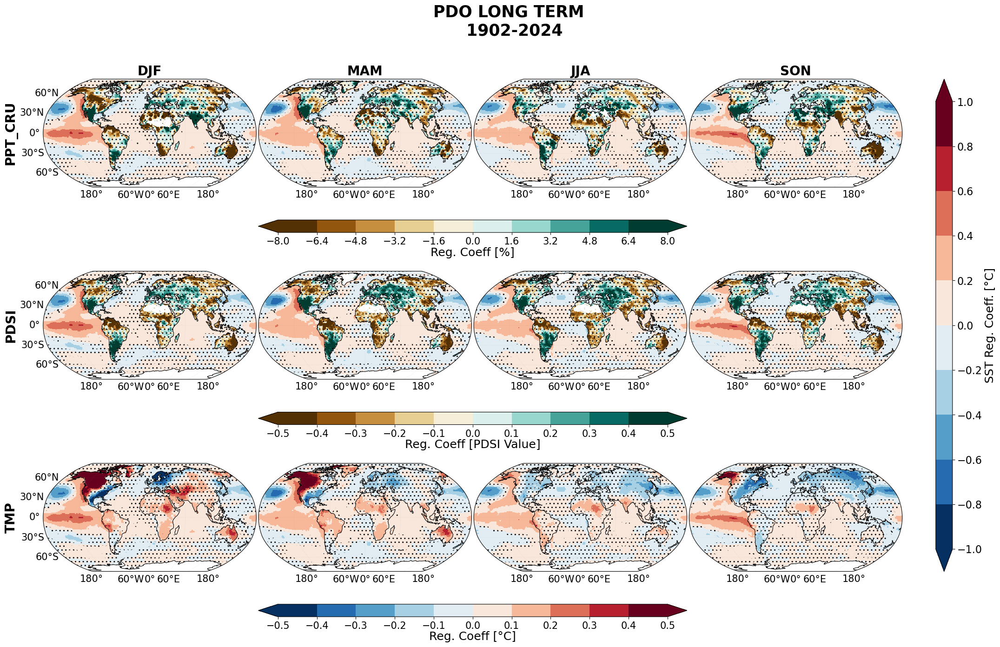

In [27]:
idx_ALL_REG_LT = utils_regression.plot_three_row_four_season_regressions(
    all_results=[
        idx_reg_ppt_sst_lt,
        idx_reg_pdsi_sst_lt,
        idx_reg_tmp_sst_lt
    ],
    var1_titles=["PPT_CRU", "PDSI", "TMP"],
    var1_labels=["Reg. Coeff [%]", "Reg. Coeff [PDSI Value]", "Reg. Coeff [°C]"],
    var1_cmaps=["BrBG", "BrBG", "RdBu_r"],
    var1_vlims=[8, 0.5, 0.5],
    sst_cmap="RdBu_r",
    sst_vlim=1.0,
    overall_title=f"{INDEX_NAME} LONG TERM \n 1902-2024"
)

In [28]:
idx_ALL_REG_LT.savefig(f"../figures/{INDEX_NAME}/{INDEX_NAME}_ALL_REG_LT.png", dpi=300, bbox_inches="tight")

# SHORT TERM REGRESSIONS

Saved PDO_PPT_GPCP_REG_ST.png


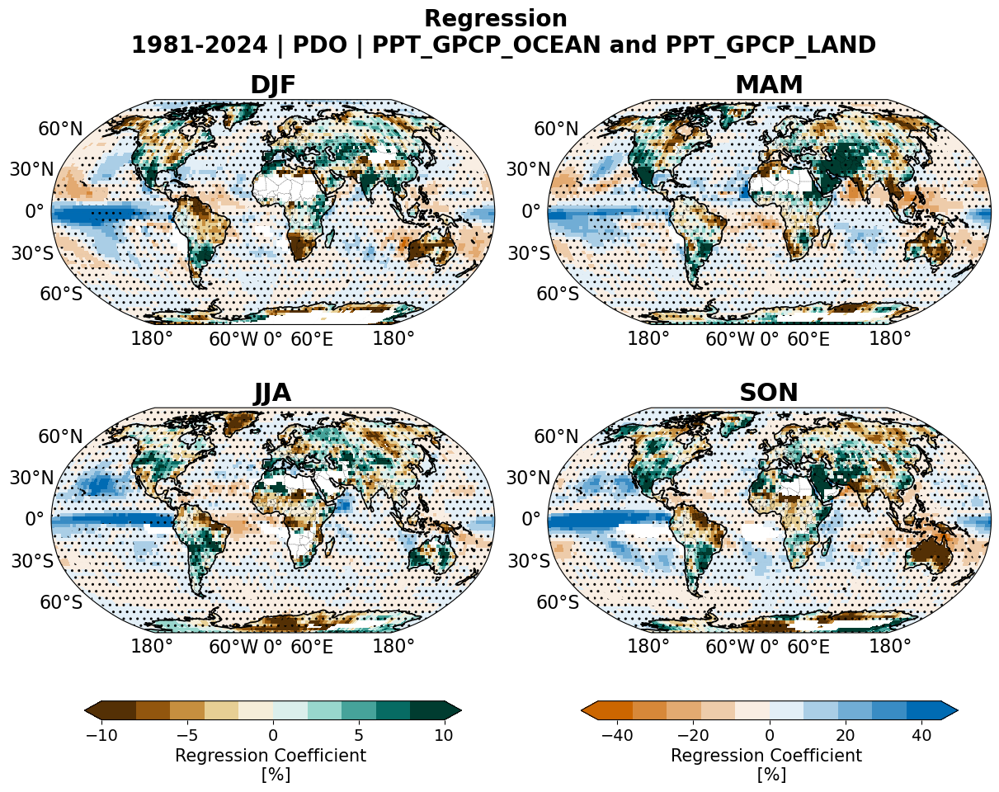

Saved ../nc_files/PDO/PDO_PPT_GPCP_REG_ST.nc


In [29]:
# PPT_GPCP
idx_reg_ppt_gpcp_st = utils_regression.compute_and_plot_reg_with_corrs_p_MOV(
    idx_values=dict(IDX_ST_dt.groupby('time.season')),
    pdsi_anoms_seasonal = PPT_GPCP_ST_LAND_dt.groupby('time.season'),
    sst_anoms_seasonal = PPT_GPCP_ST_SEA_dt.groupby('time.season'),
    years=years_1981_2024,
    seasons=['DJF', 'MAM', 'JJA', 'SON'], thresh=0.05,
    cmap_pdsi='BrBG', vlim_pdsi = 10,
    cmap_sst=OrBu, vlim_sst = 45,
    var1_name="PPT_GPCP_LAND", # <-- new
    var2_name="PPT_GPCP_OCEAN", # <-- new
    period = "ST",# <-- new
    coeff_label1='Regression Coefficient \n [%]',
    coeff_label2='Regression Coefficient \n [%]',
    index_name= INDEX_NAME,
    nc_name="PPT_GPCP",
    save_dir=f'../figures/{INDEX_NAME}/',
    nc_dir=f'../nc_files/{INDEX_NAME}/',
)

Saved PDO_SST_PPT_CRU_REG_ST.png


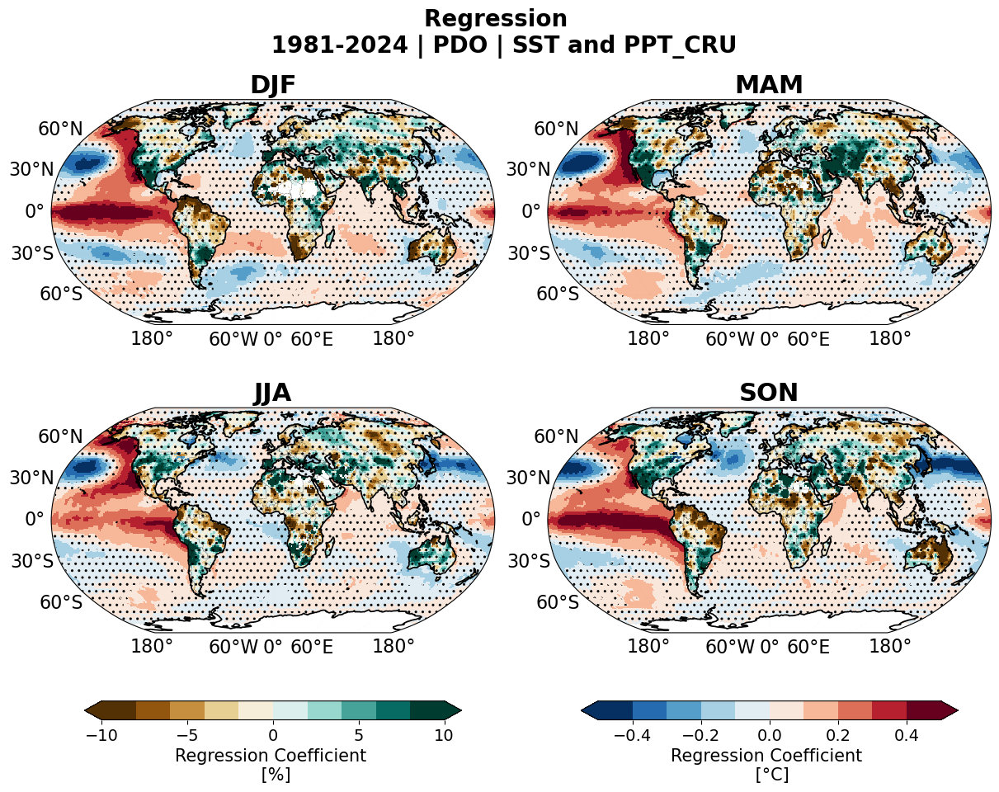

Saved ../nc_files/PDO/PDO_SST_PPT_CRU_REG_ST.nc


In [30]:
idx_reg_ppt_cru_sst_st = utils_regression.compute_and_plot_reg_with_corrs_p_MOV(
    idx_values=dict(IDX_ST_dt.groupby('time.season')),
    pdsi_anoms_seasonal=dict(PPT_CRU_ST_dt.groupby('time.season')),
    sst_anoms_seasonal=dict(SST_ST_dt.groupby('time.season')),
    years=years_1981_2024,
    seasons=['DJF', 'MAM', 'JJA', 'SON'], thresh=0.05,
    cmap_pdsi='BrBG', vlim_pdsi=10,
    cmap_sst='RdBu_r', vlim_sst=0.5,
    var1_name="PPT_CRU", # <-- new
    var2_name="SST", # <-- new
    period = "ST",# <-- new
    coeff_label1='Regression Coefficient \n [%]',
    coeff_label2='Regression Coefficient \n [°C]',
    index_name=INDEX_NAME,
    nc_name="SST_PPT_CRU",
    save_dir=f'../figures/{INDEX_NAME}/',
    nc_dir=f'../nc_files/{INDEX_NAME}/',
)

Saved PDO_SST_PDSI_REG_ST.png


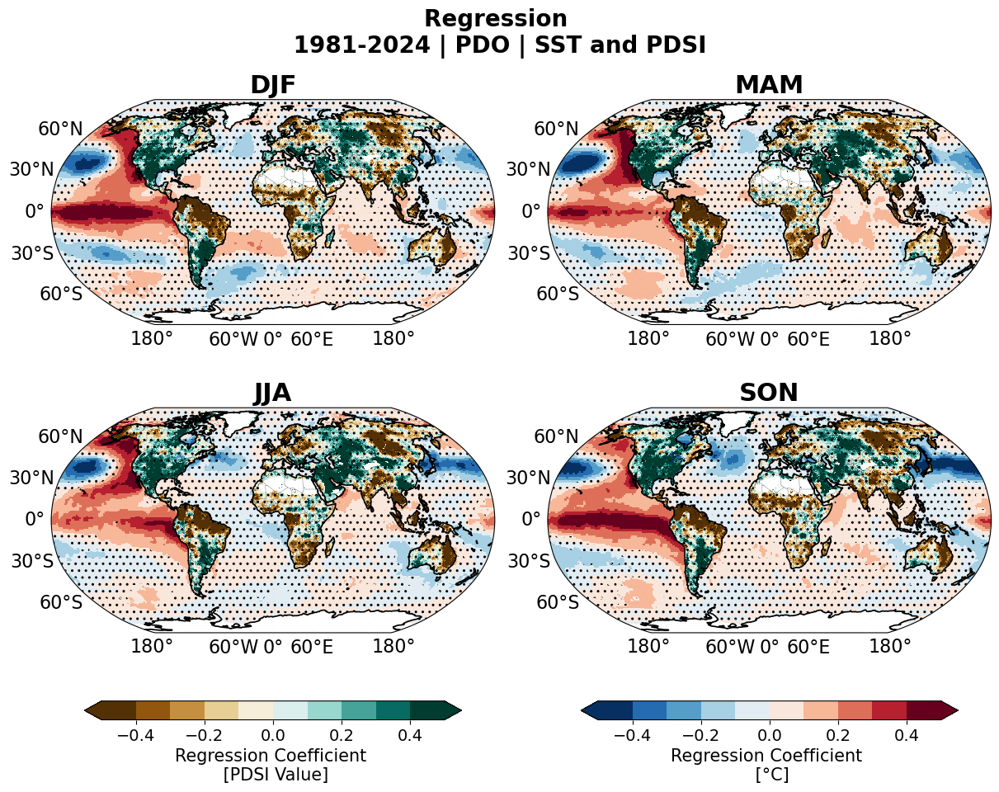

Saved ../nc_files/PDO/PDO_SST_PDSI_REG_ST.nc


In [31]:
# PDSI
idx_reg_pdsi_sst_st = utils_regression.compute_and_plot_reg_with_corrs_p_MOV(
    idx_values = IDX_ST_dt.groupby('time.season'),
    pdsi_anoms_seasonal = PDSI_ST_dt.groupby('time.season'),
    sst_anoms_seasonal = SST_ST_dt.groupby('time.season'),
    years = years_1981_2024,
    seasons=['DJF','MAM','JJA','SON'], thresh = 0.05,
    cmap_pdsi='BrBG', vlim_pdsi=0.5,
    cmap_sst='RdBu_r', vlim_sst= 0.5,
    var1_name="PDSI", # <-- new
    var2_name="SST", # <-- new
    period = "ST",# <-- new
    overall_title=f'Regression \n 1981-2024 | {INDEX_NAME} | SST and PDSI ',
    coeff_label1='Regression Coefficient \n [PDSI Value]',
    coeff_label2='Regression Coefficient \n [°C]',
    index_name=f'{INDEX_NAME}',        # <-- new
    nc_name='SST_PDSI',       # <-- new
    save_dir=f'../figures/{INDEX_NAME}/',           
    nc_dir=f'../nc_files/{INDEX_NAME}/'
)

Saved PDO_SST_SM_REG_ST.png


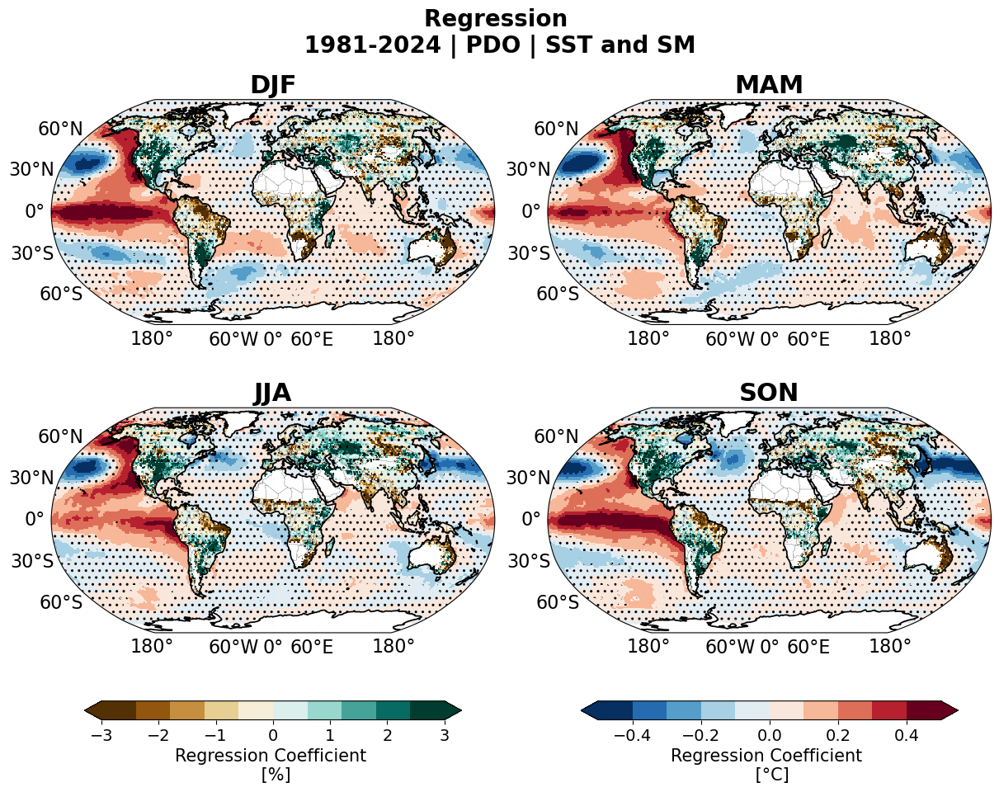

Saved ../nc_files/PDO/PDO_SST_SM_REG_ST.nc


In [32]:
# SM idx_reg_sm_sst_st['var1_reg'][0].plot.hist()
idx_reg_sm_sst_st = utils_regression.compute_and_plot_reg_with_corrs_p_MOV(
    idx_values = IDX_ST_dt.groupby('time.season'),
    pdsi_anoms_seasonal = SM_ST_dt.groupby('time.season'),
    sst_anoms_seasonal = SST_ST_dt.groupby('time.season'),
    years = years_1981_2024,
    seasons=['DJF','MAM','JJA','SON'], thresh = 0.05,
    cmap_pdsi='BrBG', vlim_pdsi = 3,
    cmap_sst='RdBu_r', vlim_sst = 0.5,
    var1_name="SM", # <-- new
    var2_name="SST", # <-- new
    period = "ST",# <-- new
    overall_title=f'Regression \n 1981-2024 | {INDEX_NAME} | SST and SM ',
    coeff_label1='Regression Coefficient \n [%]',
    coeff_label2='Regression Coefficient \n [°C]',
    index_name=f'{INDEX_NAME}',        # <-- new
    nc_name='SST_SM',       # <-- new
    save_dir=f'../figures/{INDEX_NAME}/',           
    nc_dir=f'../nc_files/{INDEX_NAME}/'
)

Saved PDO_SST_TMP_REG_ST.png


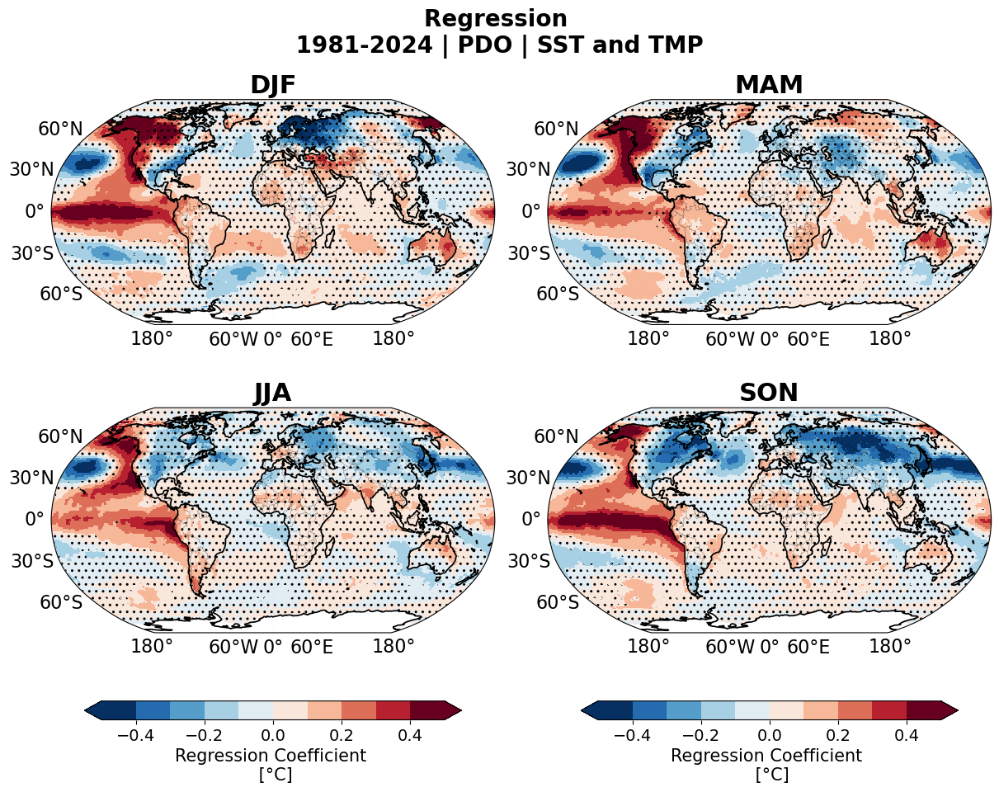

Saved ../nc_files/PDO/PDO_SST_TMP_REG_ST.nc


In [33]:
# TMP idx_reg_tmp_sst_st['var1_reg'][0].plot.hist()
idx_reg_tmp_sst_st = utils_regression.compute_and_plot_reg_with_corrs_p_MOV(
    idx_values = IDX_ST_dt.groupby('time.season'),
    pdsi_anoms_seasonal = TMP_ST_dt.groupby('time.season'),
    sst_anoms_seasonal = SST_ST_dt.groupby('time.season'),
    years = years_1981_2024,
    seasons=['DJF','MAM','JJA','SON'], thresh = 0.05,
    cmap_pdsi='RdBu_r', vlim_pdsi=0.5,
    cmap_sst='RdBu_r', vlim_sst= 0.5,
    var1_name="TMP", # <-- new
    var2_name="SST", # <-- new
    period = "ST",# <-- new
    overall_title=f'Regression \n 1981-2024 | {INDEX_NAME} | SST and TMP ',
    coeff_label1='Regression Coefficient \n [°C]',
    coeff_label2='Regression Coefficient \n [°C]',
    index_name=f'{INDEX_NAME}',        # <-- new
    nc_name='SST_TMP',       # <-- new
    save_dir=f'../figures/{INDEX_NAME}/',           
    nc_dir=f'../nc_files/{INDEX_NAME}/'
)

## PLOT ALL 

### ALL ST REG

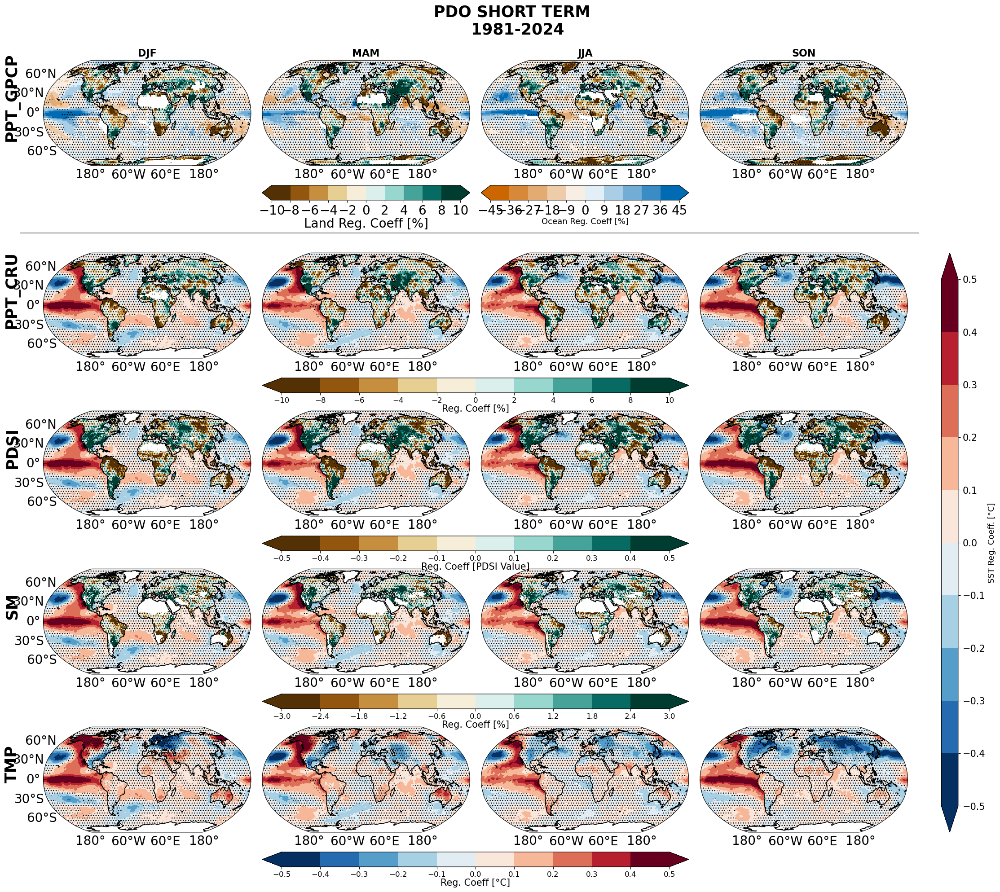

In [34]:
idx_reg_st_all = utils_regression.plot_five_row_four_season_regressions(
    all_results=[
        idx_reg_ppt_gpcp_st,
        idx_reg_ppt_cru_sst_st,
        idx_reg_pdsi_sst_st,
        idx_reg_sm_sst_st,
        idx_reg_tmp_sst_st
    ],
    var1_titles=["PPT_GPCP", "PPT_CRU", "PDSI", "SM", "TMP"],
    var1_labels=["Land Reg. Coeff [%]", "Reg. Coeff [%]",
                 "Reg. Coeff [PDSI Value]", "Reg. Coeff [%]",
                 "Reg. Coeff [°C]"],
    var1_cmaps=["BrBG", "BrBG", "BrBG", "BrBG", "RdBu_r"],
    var1_vlims=[10, 10, 0.5, 3.0, 0.5],
    sst_cmap="RdBu_r",
    sst_vlim=0.5,
    # Row 0 overrides:
    row0_var1_cmap="BrBG",
    row0_var1_vlim=10,
    row0_sst_cmap=OrBu,
    row0_sst_vlim=45,
    overall_title=f"{INDEX_NAME} SHORT TERM \n 1981-2024"
)

In [35]:
idx_reg_st_all.savefig(f"../figures/{INDEX_NAME}/{INDEX_NAME}_ALL_REG_ST.png", 
                       dpi=300, bbox_inches="tight")

# AGREEMENT TIMESERIES

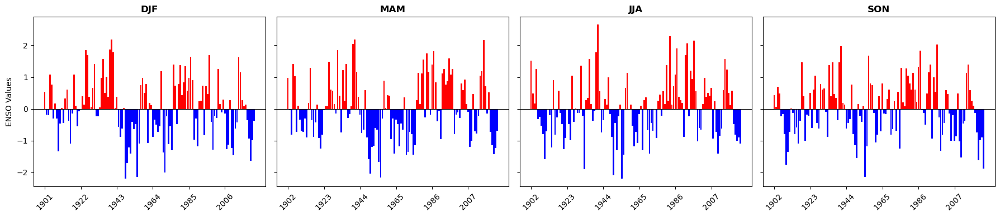

In [36]:
utils_agreement.plot_index_seasons(IDX_LT_dt.groupby("time.season"))

## ST

In [26]:
# ── Shared settings ───
shared_agreement_top_st = dict(
    sst_seasonal_indices_LT = dict(IDX_ST_dt.groupby('time.season')),
    index_name    = INDEX_NAME,
    pos_label     = POS_LABEL,
    neg_label     = NEG_LABEL,
    period        = "ST",
    seasons       = ("DJF", "MAM", "JJA", "SON"),
    phase         = "top",
    phase_title   = f"Agreement Composite \n {INDEX_NAME} | Top 15% | Short Term [1981-2024]",
    pct           = 0.15,
    max_n         = 7,
    threshold     = 1,
    disagreement_thresh = 1,
    disagree_color = "#A9A9A9",
    thr_white     = 1,
    save_dir      = f'../figures/{INDEX_NAME}/',
    nc_dir        = f'../nc_files/{INDEX_NAME}/',
)

shared_agreement_bottom_st = {
    **shared_agreement_top_st,
    "phase": "bottom",
    "phase_title": f"Agreement Composite \n {INDEX_NAME} | Bottom 15% | Short Term [1981-2024]",
}

Saved ../figures/PDO/PDO_PPT_GPCP_AGR_TOP_ST.png
Saved ../nc_files/PDO/PDO_PPT_GPCP_AGR_TOP_ST.nc


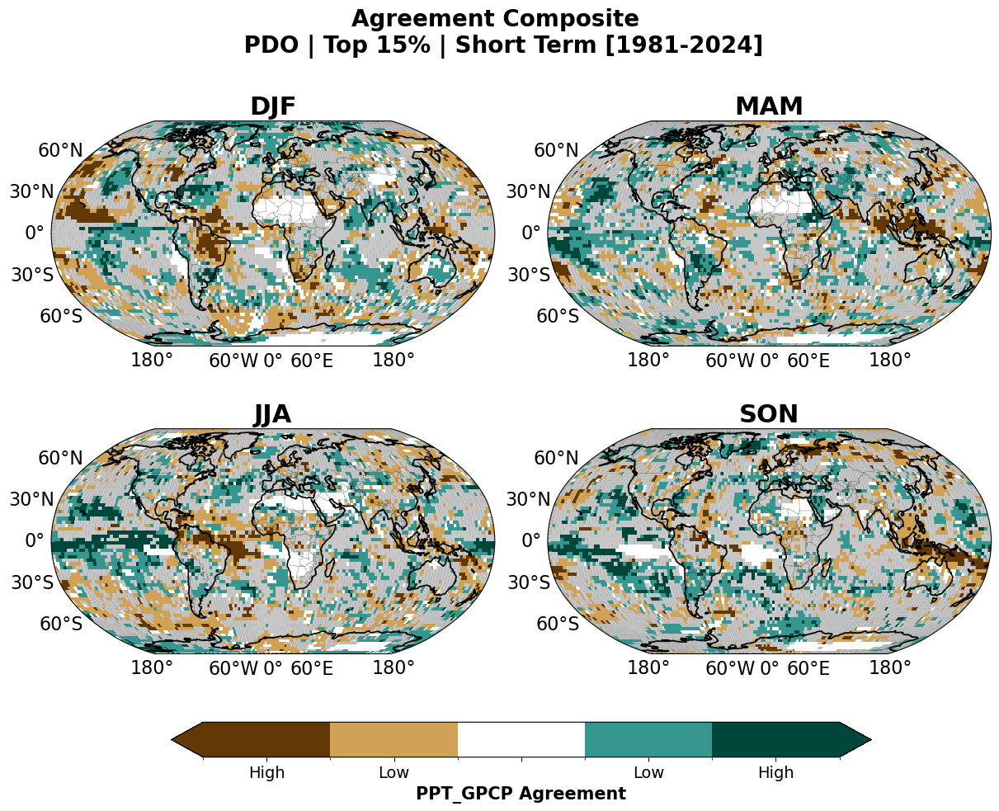

In [38]:
idx_PPT_GPCP_AGR_TOP_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PPT_GPCP",
    data_group  = PPT_GPCP_ST_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_top_st,
)
plt.show()

Saved ../figures/PDO/PDO_PPT_GPCP_AGR_BOT_ST.png
Saved ../nc_files/PDO/PDO_PPT_GPCP_AGR_BOT_ST.nc


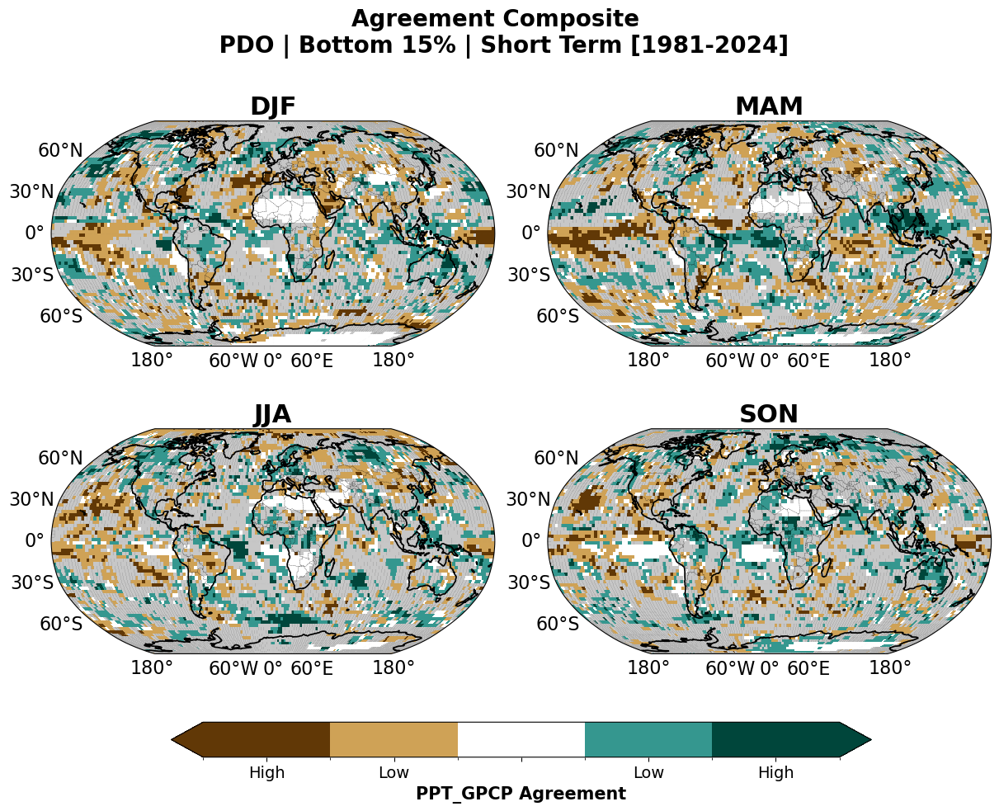

In [39]:
idx_PPT_GPCP_AGR_BOT_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PPT_GPCP",
    data_group  = PPT_GPCP_ST_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_bottom_st,
)

plt.show()


Saved ../figures/PDO/PDO_SST_AGR_TOP_ST.png
Saved ../nc_files/PDO/PDO_SST_AGR_TOP_ST.nc


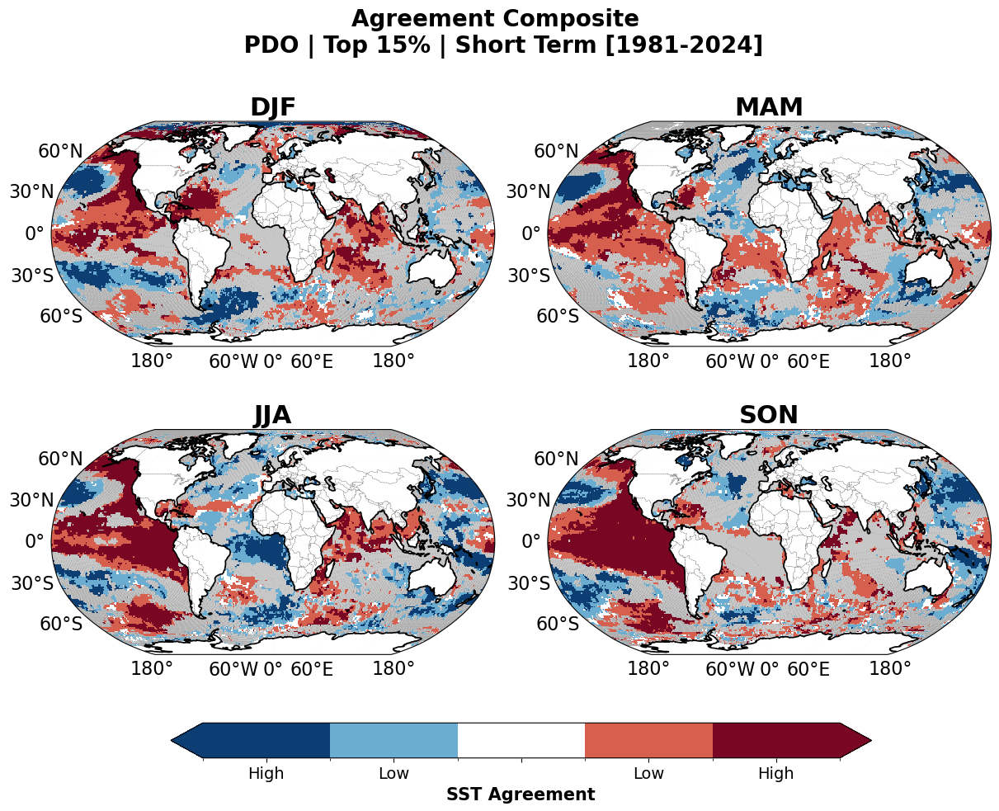

In [27]:
# ── Call it once per variable ───
idx_SST_AGR_TOP_ST = utils_agreement.plot_var_agreement_2x2(
    var_label    = "SST",
    data_group   = dict(SST_ST_dt.groupby('time.season')),
    cmap_name    = "RdBu_r",
    vmax         = 7,
    breaks       = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_top_st,
) 

## File will not save if there is already an .nc file with the same name. 

Saved ../figures/PDO/PDO_SST_AGR_BOT_ST.png
Saved ../nc_files/PDO/PDO_SST_AGR_BOT_ST.nc


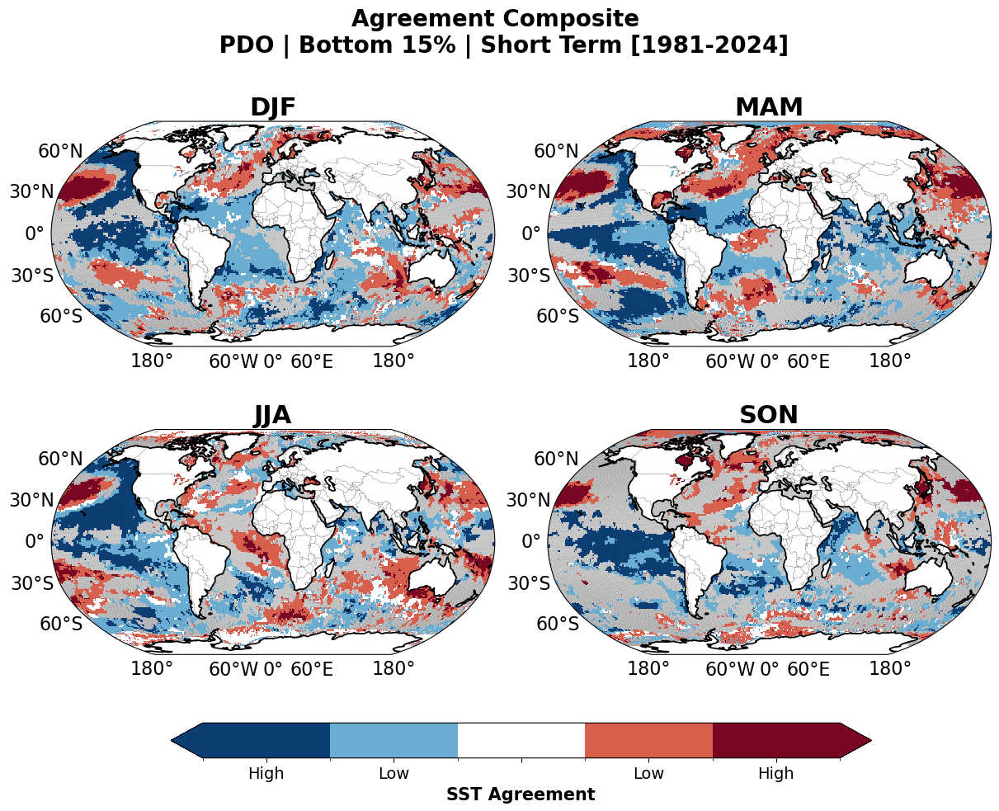

In [41]:
idx_SST_AGR_BOT_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "SST",
    data_group  = SST_ST_dt.groupby('time.season'),
    cmap_name   = "RdBu_r",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_bottom_st,
)

plt.show()

Saved ../figures/PDO/PDO_PPT_CRU_AGR_TOP_ST.png
Saved ../nc_files/PDO/PDO_PPT_CRU_AGR_TOP_ST.nc


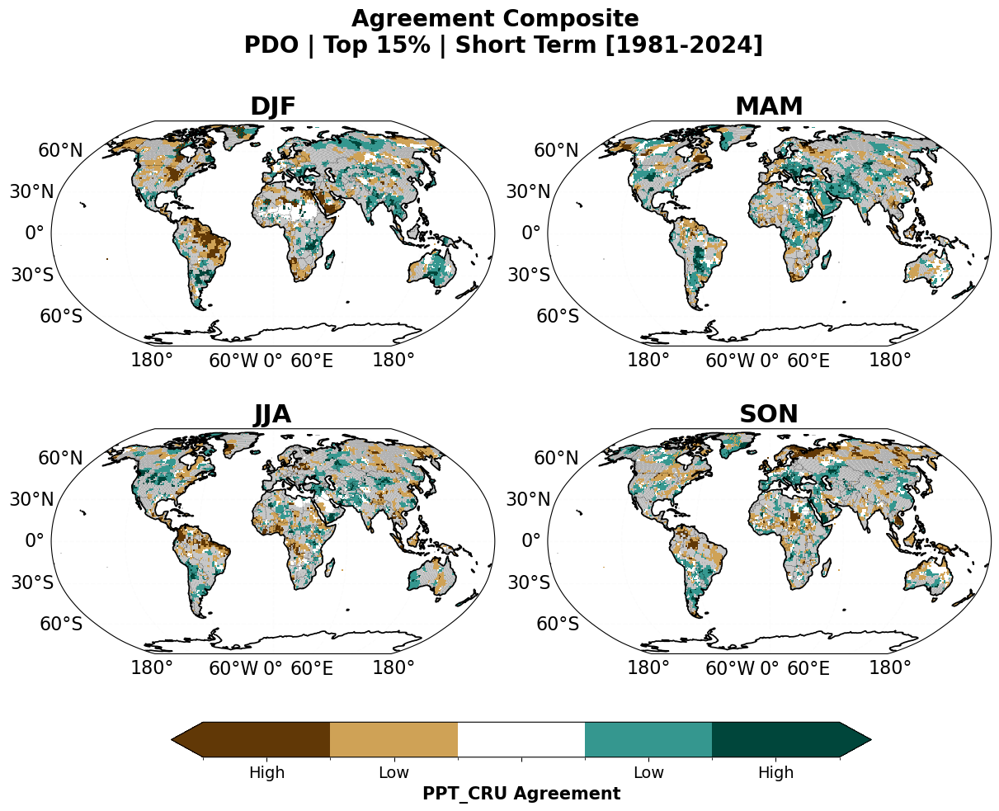

Saved ../figures/PDO/PDO_PPT_CRU_AGR_BOT_ST.png
Saved ../nc_files/PDO/PDO_PPT_CRU_AGR_BOT_ST.nc


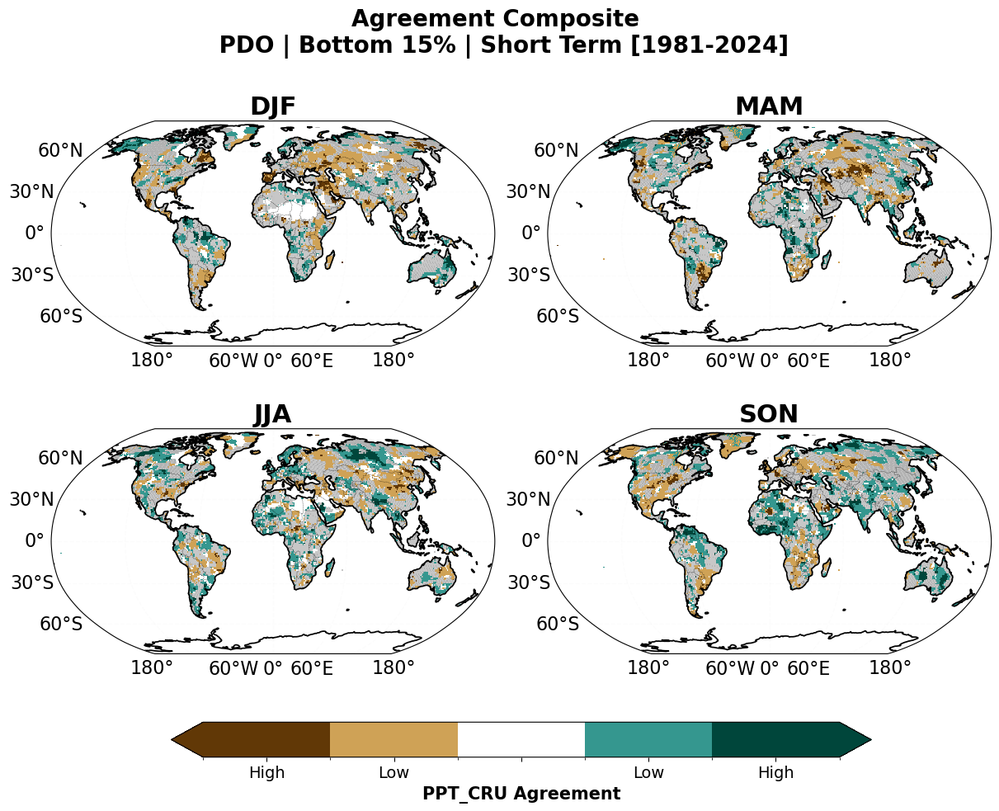

In [42]:
idx_PPT_CRU_AGR_TOP_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PPT_CRU",
    data_group  = PPT_CRU_ST_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_top_st,
)
plt.show()

idx_PPT_CRU_AGR_BOT_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PPT_CRU",
    data_group  = PPT_CRU_ST_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_bottom_st,
)

plt.show()


Saved ../figures/PDO/PDO_PDSI_AGR_TOP_ST.png
Saved ../nc_files/PDO/PDO_PDSI_AGR_TOP_ST.nc


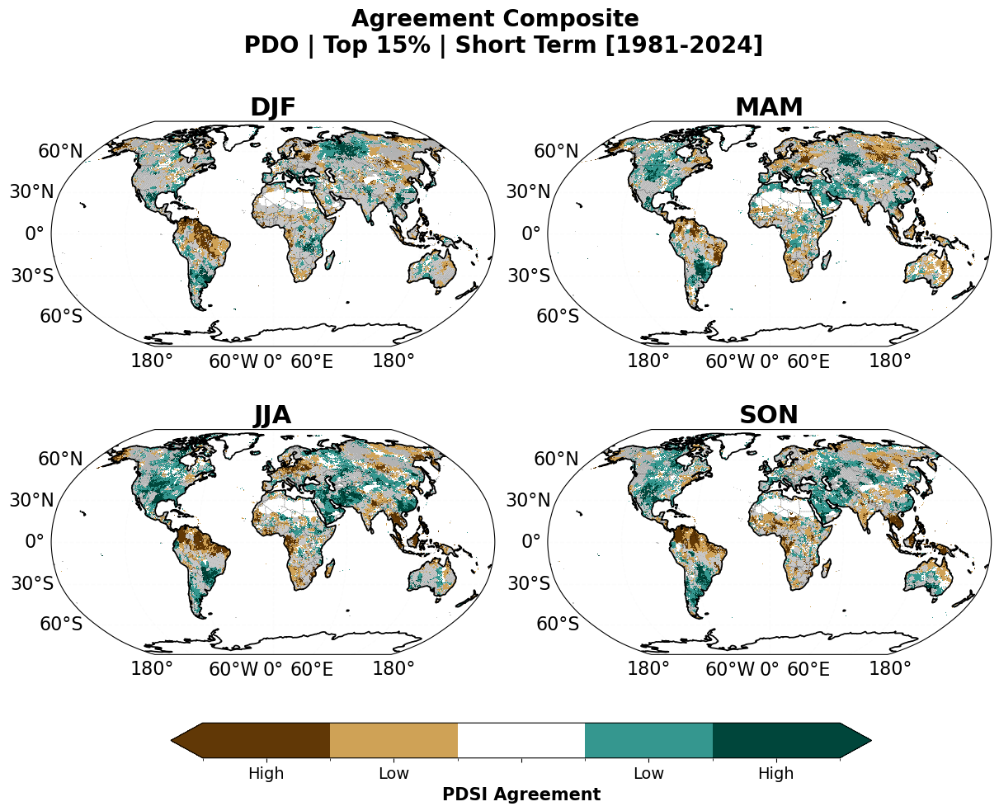

Saved ../figures/PDO/PDO_PDSI_AGR_BOT_ST.png
Saved ../nc_files/PDO/PDO_PDSI_AGR_BOT_ST.nc


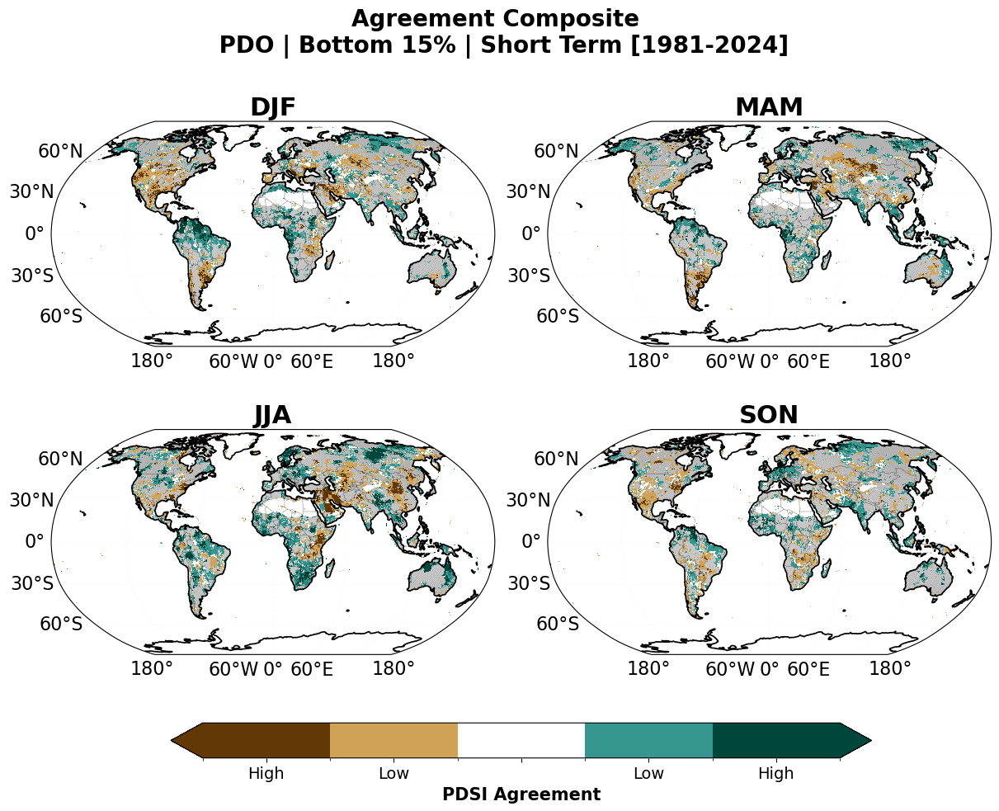

In [43]:
idx_PDSI_AGR_TOP_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PDSI",
    data_group  = PDSI_ST_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_top_st,
)
plt.show()

idx_PDSI_AGR_BOT_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PDSI",
    data_group  = PDSI_ST_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_bottom_st,
)

plt.show()

Saved ../figures/PDO/PDO_SM_AGR_TOP_ST.png
Saved ../nc_files/PDO/PDO_SM_AGR_TOP_ST.nc


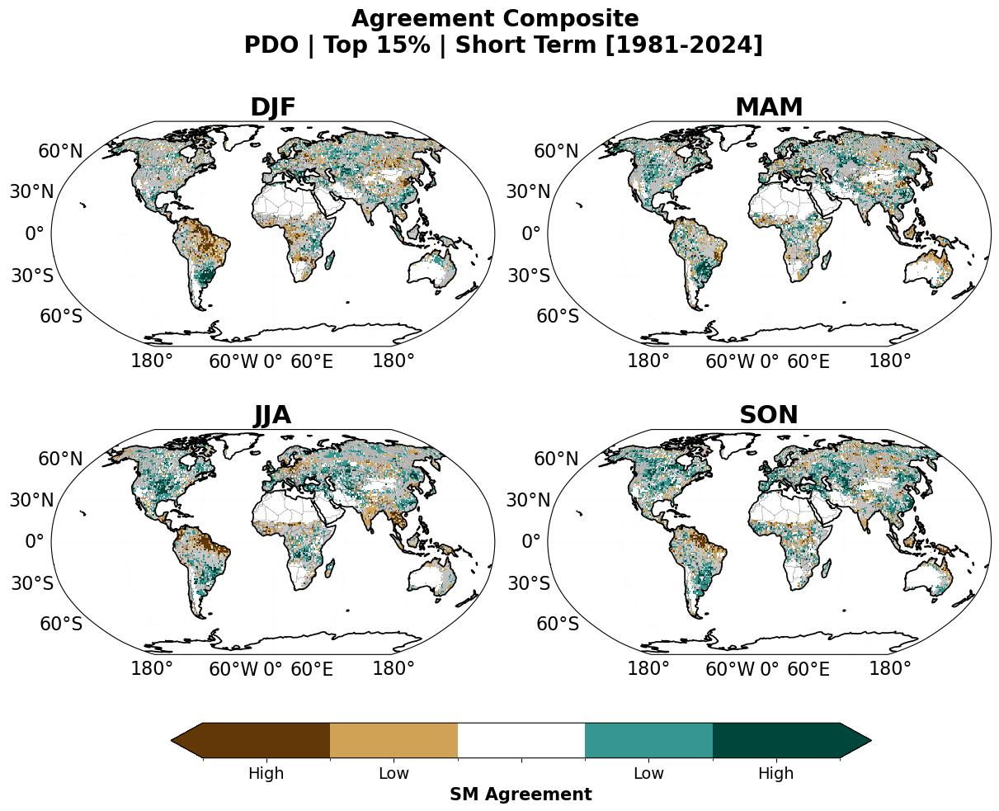

Saved ../figures/PDO/PDO_SM_AGR_BOT_ST.png
Saved ../nc_files/PDO/PDO_SM_AGR_BOT_ST.nc


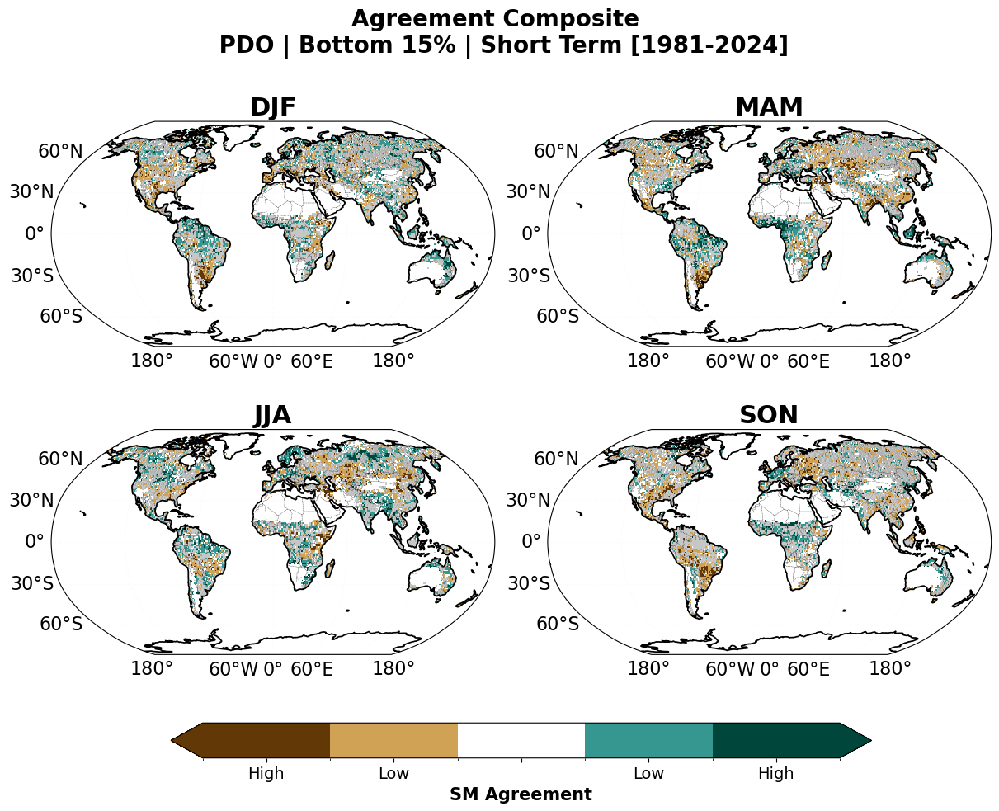

In [44]:
idx_SM_AGR_TOP_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "SM",
    data_group  = SM_ST_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_top_st,
)
plt.show()

idx_SM_AGR_BOT_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "SM",
    data_group  = SM_ST_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_bottom_st,
)

plt.show()


In [24]:
idx_TMP_AGR_TOP_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "TMP",
    data_group  = TMP_ST_dt.groupby('time.season'),
    cmap_name   = "RdBu_r",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_top_st,
)
plt.show()



idx_TMP_AGR_BOT_ST = utils_agreement.plot_var_agreement_2x2(
    var_label   = "TMP",
    data_group  = TMP_ST_dt.groupby('time.season'),
    cmap_name   = "RdBu_r",
    vmax        = 7,
    breaks      = 3,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_bottom_st,
)

plt.show()

NameError: name 'shared_agreement_top_st' is not defined

### Combined 

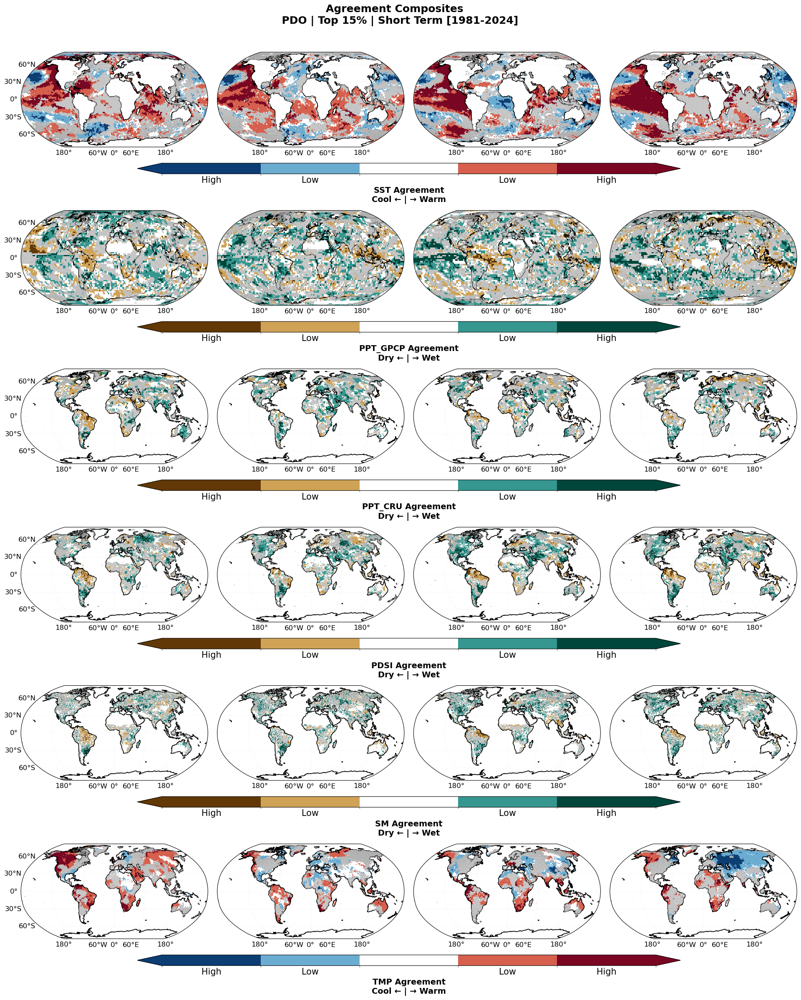

In [46]:
# Top 15% [ST]
idx_ALL_AGR_TOP_ST = utils_agreement.plot_index_agreement_by_season_ST(
    sst_seasonal_indices_LT  = IDX_ST_dt.groupby('time.season'),
    SST_Anom_1903_2023       = SST_ST_dt.groupby('time.season'),
    PPT_GPCP_Anom_1903_2023  = PPT_GPCP_ST_dt.groupby('time.season'),
    PPT_CRU_Anom_1903_2023   = PPT_CRU_ST_dt.groupby('time.season'),
    PDSI_Anom_1903_2023      = PDSI_ST_dt.groupby('time.season'),
    SM_Anom_1903_2023        = SM_ST_dt.groupby('time.season'),
    TMP_Anom_1903_2023       = TMP_ST_dt.groupby('time.season'),
    phase="top",
    phase_title="Top 15%",
)

idx_ALL_AGR_TOP_ST.savefig(f"../figures/{INDEX_NAME}/{INDEX_NAME}_ALL_AGR_TOP_ST.png", dpi=300, bbox_inches="tight")

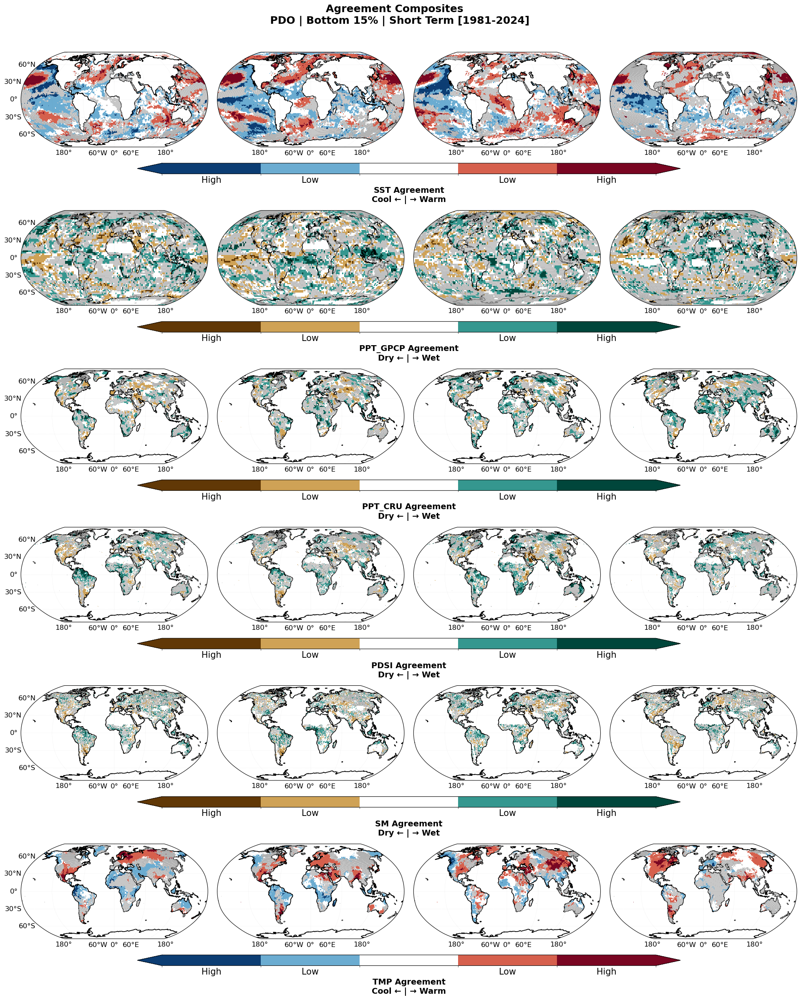

In [47]:
# BOTTOM 15% [ST]
idx_ALL_AGR_BOT_ST = utils_agreement.plot_index_agreement_by_season_ST(
    sst_seasonal_indices_LT  = IDX_ST_dt.groupby('time.season'),
    SST_Anom_1903_2023       = SST_ST_dt.groupby('time.season'),
    PPT_GPCP_Anom_1903_2023  = PPT_GPCP_ST_dt.groupby('time.season'),
    PPT_CRU_Anom_1903_2023   = PPT_CRU_ST_dt.groupby('time.season'),
    PDSI_Anom_1903_2023      = PDSI_ST_dt.groupby('time.season'),
    SM_Anom_1903_2023        = SM_ST_dt.groupby('time.season'),
    TMP_Anom_1903_2023       = TMP_ST_dt.groupby('time.season'),
    phase="bottom",
    phase_title="Bottom 15%",
)

idx_ALL_AGR_BOT_ST.savefig(f"../figures/{INDEX_NAME}/{INDEX_NAME}_ALL_AGR_BOT_ST.png", dpi=300, bbox_inches="tight")

## LT 

In [48]:
shared_agreement_top_lt = dict(
    sst_seasonal_indices_LT = dict(IDX_LT_dt.groupby('time.season')),
    index_name    = INDEX_NAME,
    pos_label     = POS_LABEL,
    neg_label     = NEG_LABEL,
    period        = "LT",
    seasons       = ("DJF", "MAM", "JJA", "SON"),
    phase         = "top",
    phase_title   = f"Agreement Composite \n {INDEX_NAME} | Top 15% | Long Term [1902-2024]",
    pct           = 0.15,
    max_n         = 18,
    threshold     = 3,
    disagreement_thresh = 3,
    disagree_color = "#A9A9A9",
    thr_white     = 3,
    save_dir      = f'../figures/{INDEX_NAME}/',
    nc_dir        = f'../nc_files/{INDEX_NAME}/',
)

shared_agreement_bottom_lt = {
    **shared_agreement_top_lt,
    "phase": "bottom",
    "phase_title": f"Agreement Composite \n {INDEX_NAME} | Bottom 15% | Long Term [1902-2024]",
}


Saved ../figures/PDO/PDO_SST_AGR_TOP_LT.png
Saved ../nc_files/PDO/PDO_SST_AGR_TOP_LT.nc


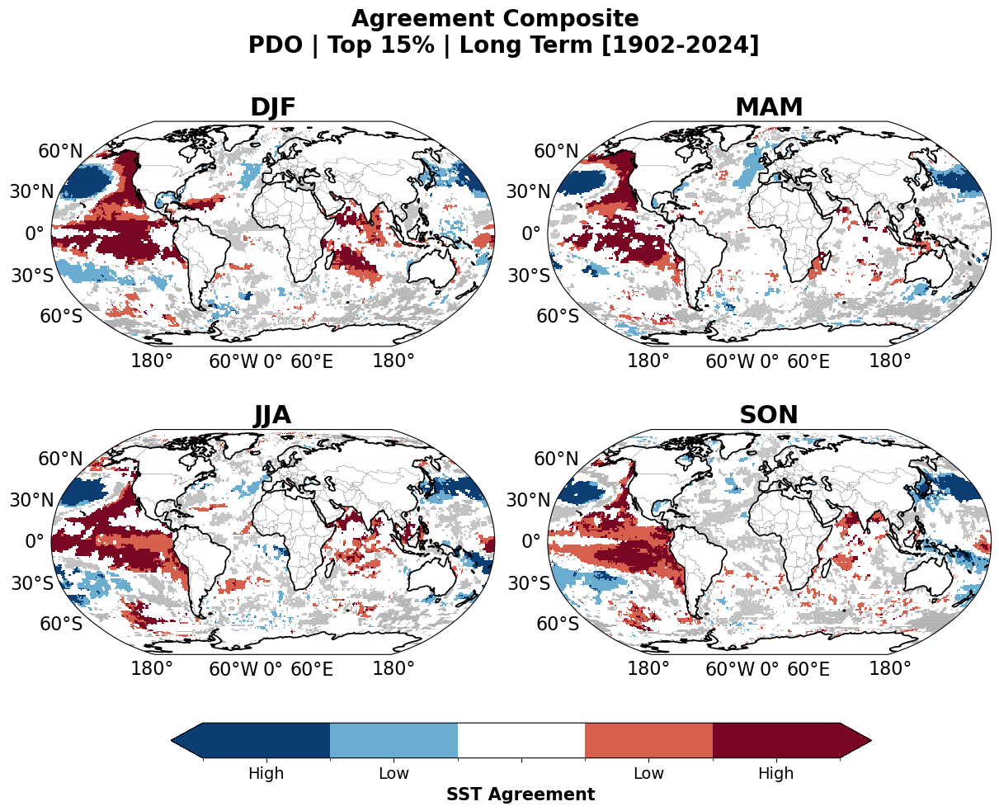

Saved ../figures/PDO/PDO_SST_AGR_BOT_LT.png
Saved ../nc_files/PDO/PDO_SST_AGR_BOT_LT.nc


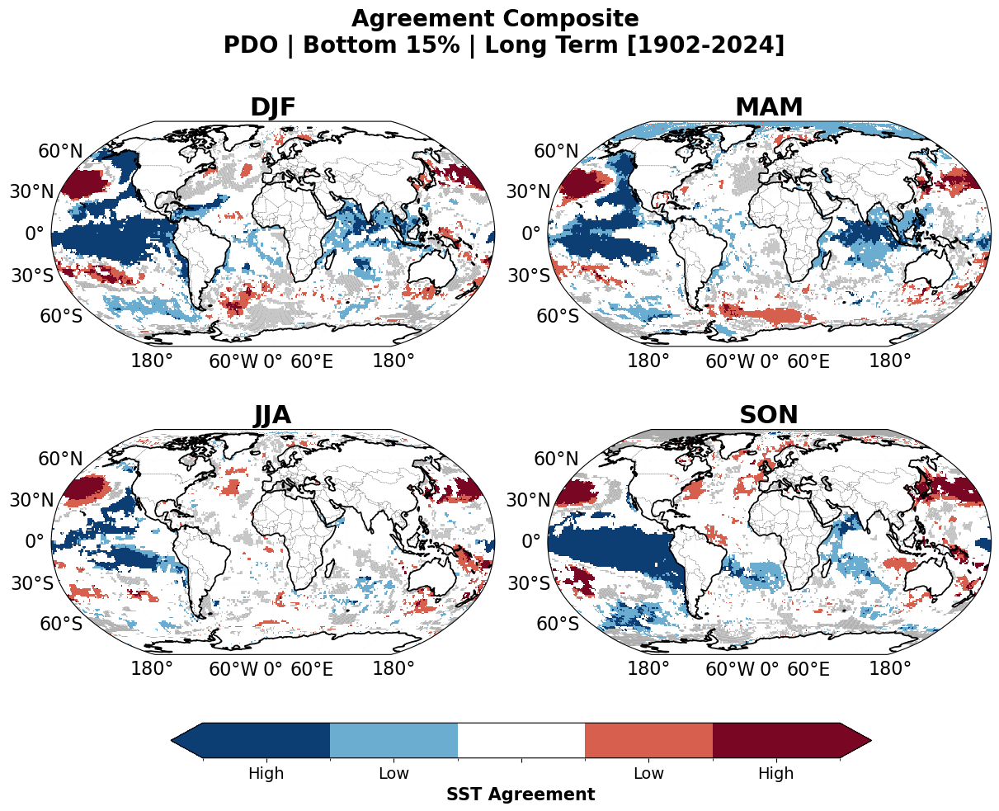

In [49]:
idx_SST_AGR_TOP_LT = utils_agreement.plot_var_agreement_2x2(
    var_label   = "SST",
    data_group  = SST_LT_dt.groupby('time.season'),
    cmap_name   = "RdBu_r",
    vmax        = 18,
    breaks      = 7,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_top_lt,
)

plt.show()

idx_SST_AGR_BOT_LT = utils_agreement.plot_var_agreement_2x2(
    var_label   = "SST",
    data_group  = SST_LT_dt.groupby('time.season'),
    cmap_name   = "RdBu_r",
    vmax        = 18,
    breaks      = 7,
    is_ocean_var = True,
    overwrite = True, 
    **shared_agreement_bottom_lt,
)

plt.show()

Saved ../figures/PDO/PDO_PPT_CRU_AGR_TOP_LT.png
Saved ../nc_files/PDO/PDO_PPT_CRU_AGR_TOP_LT.nc


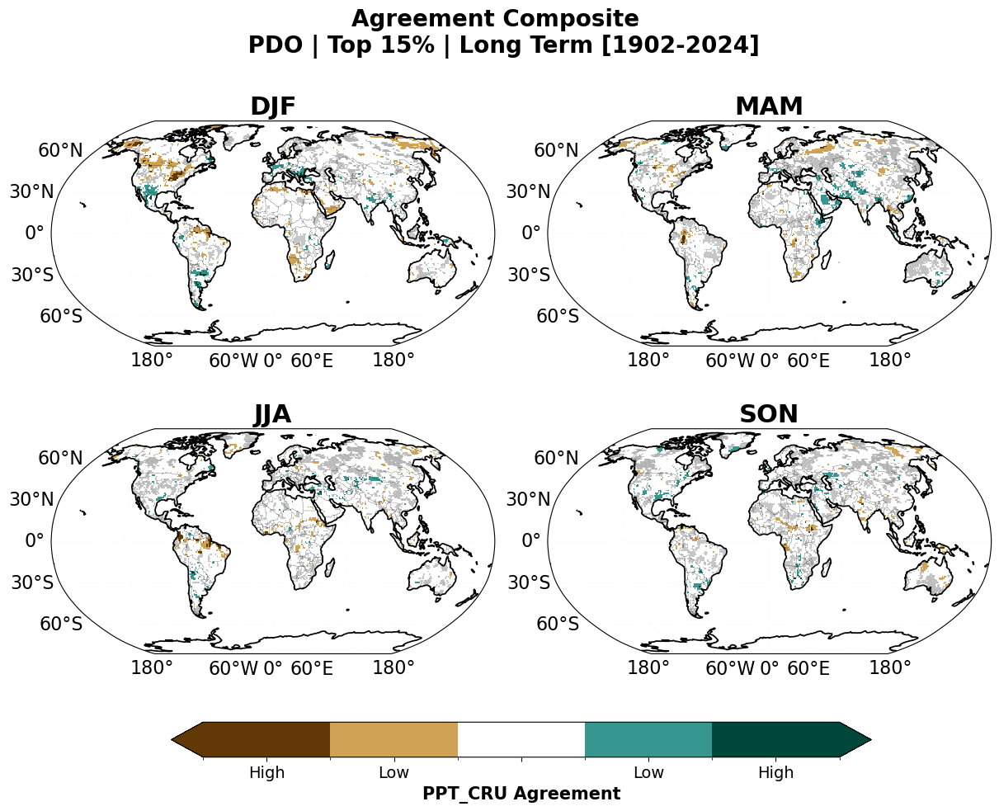

Saved ../figures/PDO/PDO_PPT_CRU_AGR_BOT_LT.png
Saved ../nc_files/PDO/PDO_PPT_CRU_AGR_BOT_LT.nc


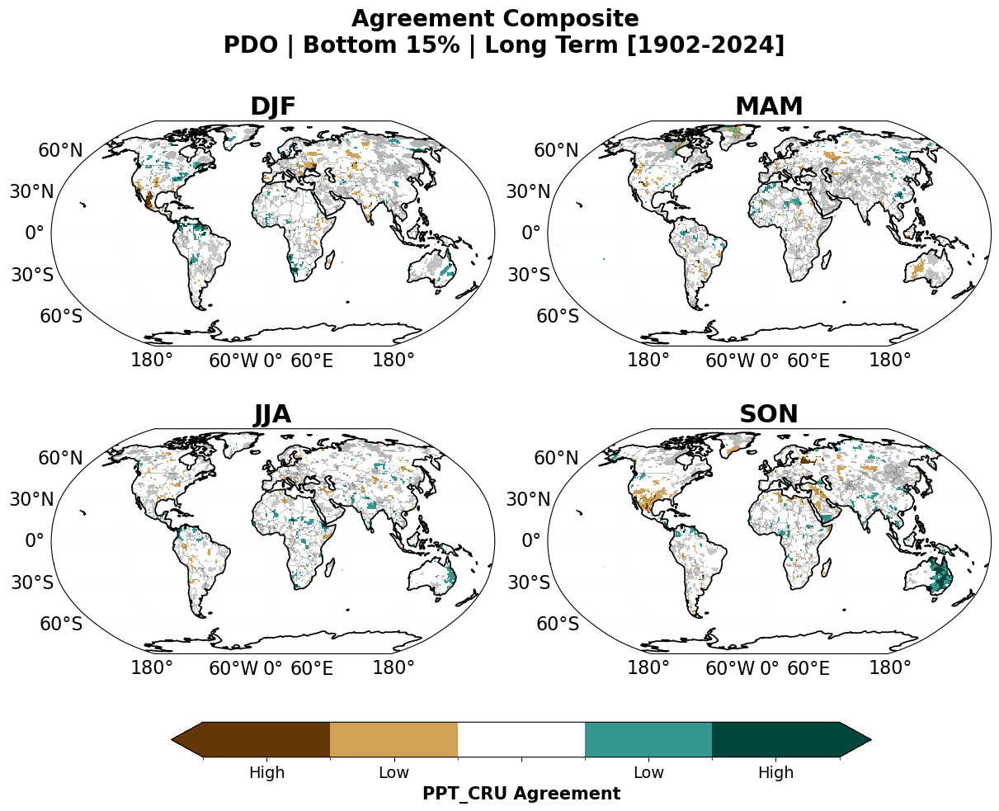

In [50]:
idx_PPT_CRU_AGR_TOP_LT = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PPT_CRU",
    data_group  = PPT_LT_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 18,
    breaks      = 7,
    is_ocean_var = True,
    overwrite = True,
    **shared_agreement_top_lt,
)
plt.show()

idx_PPT_CRU_AGR_BOT_LT = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PPT_CRU",
    data_group  = PPT_LT_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 18,
    breaks      = 7,
    is_ocean_var = True,
    overwrite = True,
    **shared_agreement_bottom_lt,
)

plt.show()

Saved ../figures/PDO/PDO_PDSI_AGR_TOP_LT.png
Saved ../nc_files/PDO/PDO_PDSI_AGR_TOP_LT.nc


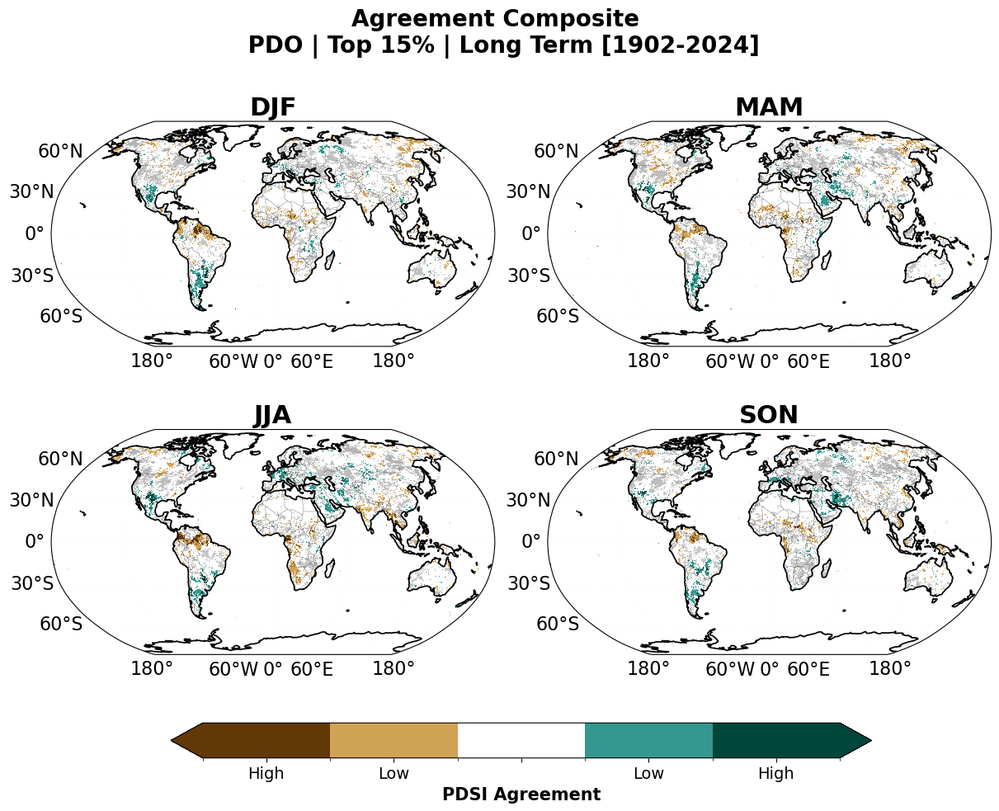

Saved ../figures/PDO/PDO_PDSI_AGR_BOT_LT.png
Saved ../nc_files/PDO/PDO_PDSI_AGR_BOT_LT.nc


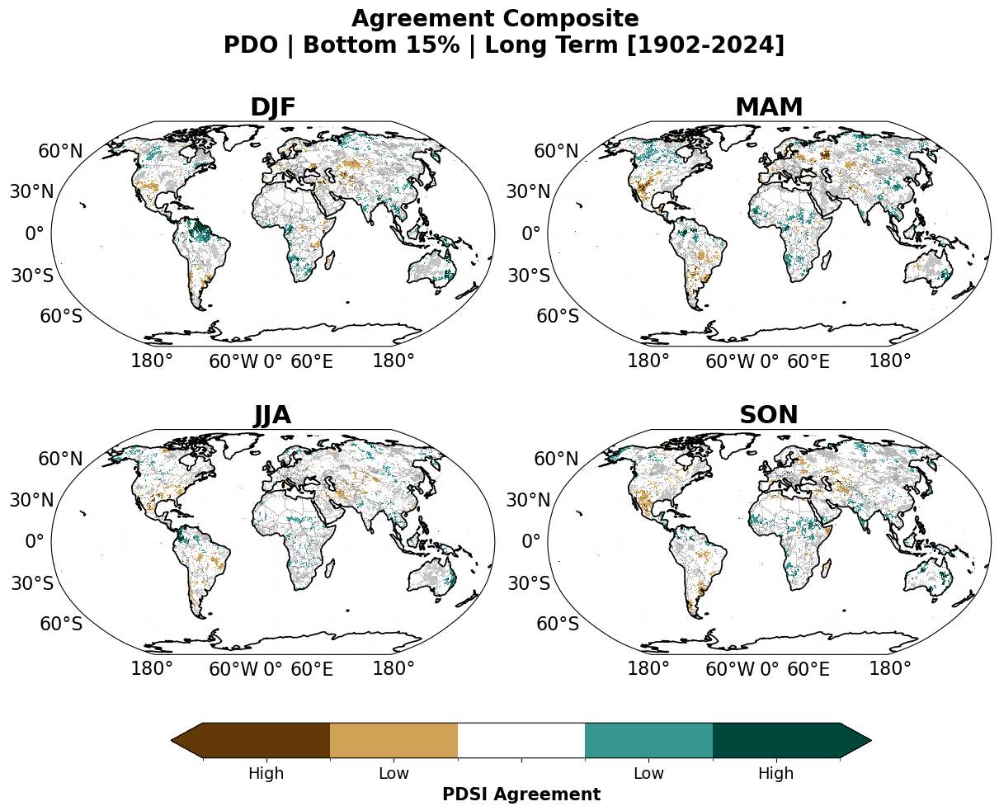

In [51]:
idx_PDSI_AGR_TOP_LT = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PDSI",
    data_group  = PDSI_LT_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 18,
    breaks      = 7,
    is_ocean_var = True,
    overwrite = True,
    **shared_agreement_top_lt,
)
plt.show()

idx_PDSI_AGR_BOT_LT = utils_agreement.plot_var_agreement_2x2(
    var_label   = "PDSI",
    data_group  = PDSI_LT_dt.groupby('time.season'),
    cmap_name   = "BrBG",
    vmax        = 18,
    breaks      = 7,
    is_ocean_var = True,
    overwrite = True,
    **shared_agreement_bottom_lt,
)

plt.show()

Saved ../figures/PDO/PDO_TMP_AGR_TOP_LT.png
Saved ../nc_files/PDO/PDO_TMP_AGR_TOP_LT.nc


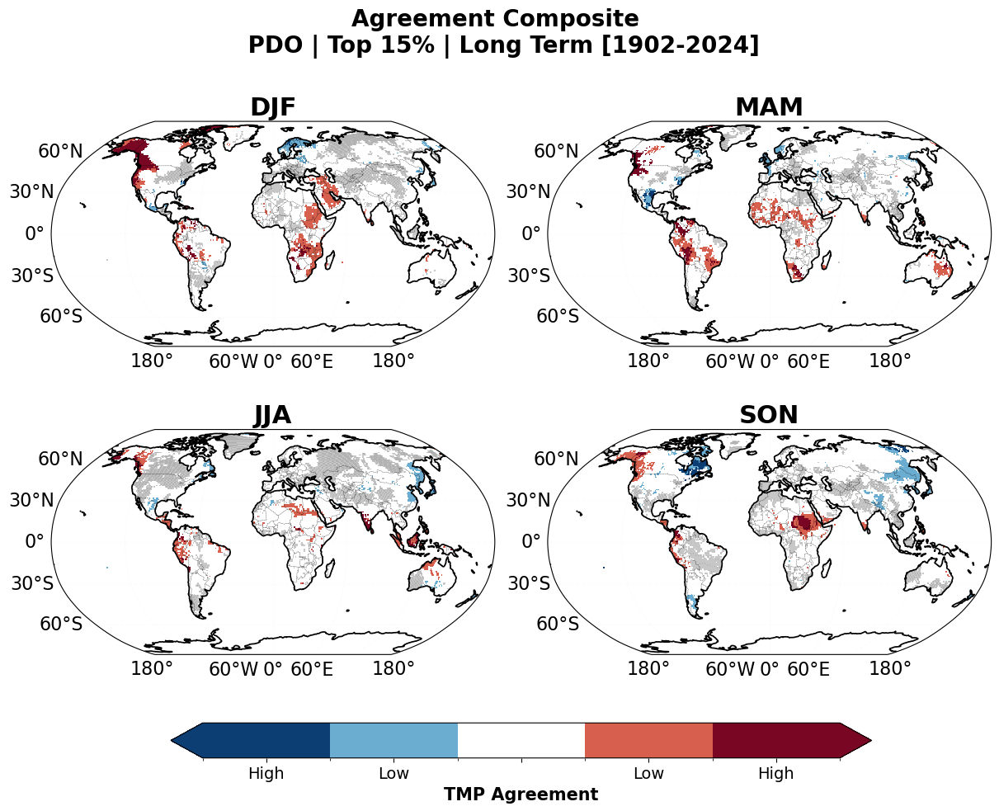

Saved ../figures/PDO/PDO_TMP_AGR_BOT_LT.png
Saved ../nc_files/PDO/PDO_TMP_AGR_BOT_LT.nc


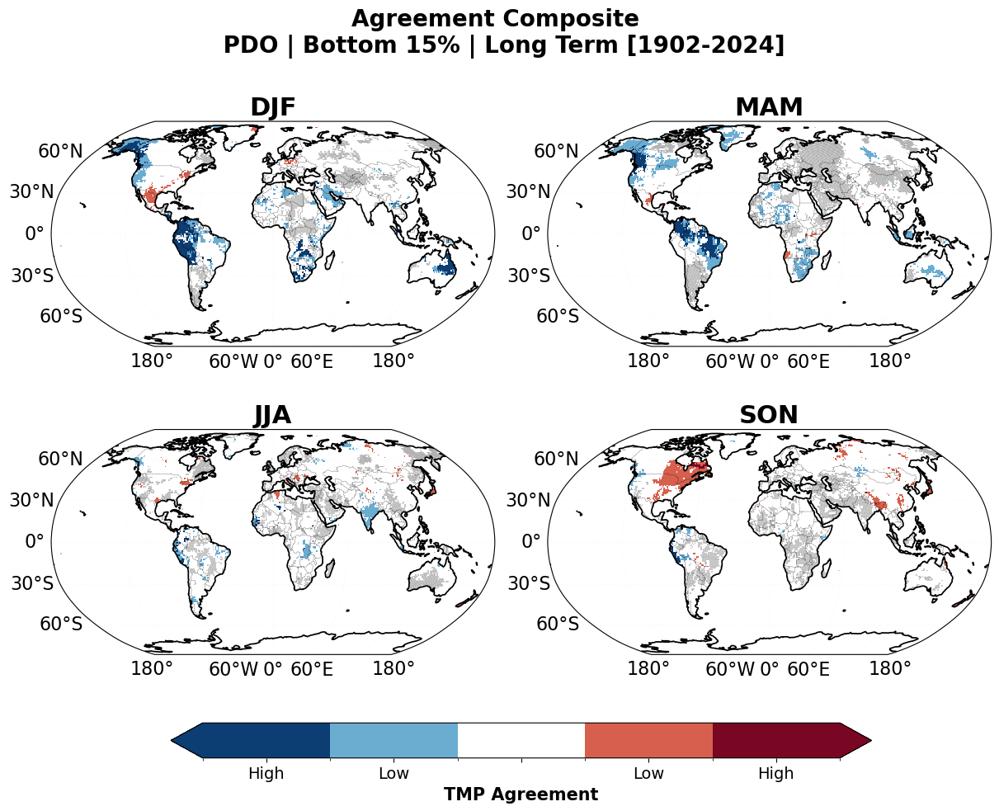

In [52]:
idx_TMP_AGR_TOP_LT = utils_agreement.plot_var_agreement_2x2(
    var_label   = "TMP",
    data_group  = TMP_LT_dt.groupby('time.season'),
    cmap_name   = "RdBu_r",
    vmax        = 18,
    breaks      = 7,
    is_ocean_var = True,
    overwrite = True,
    **shared_agreement_top_lt,
)
plt.show()

idx_TMP_AGR_BOT_LT = utils_agreement.plot_var_agreement_2x2(
    var_label   = "TMP",
    data_group  = TMP_LT_dt.groupby('time.season'),
    cmap_name   = "RdBu_r",
    vmax        = 18,
    breaks      = 7,
    is_ocean_var = True,
    overwrite = True,
    **shared_agreement_bottom_lt,
)

plt.show()

### Combined

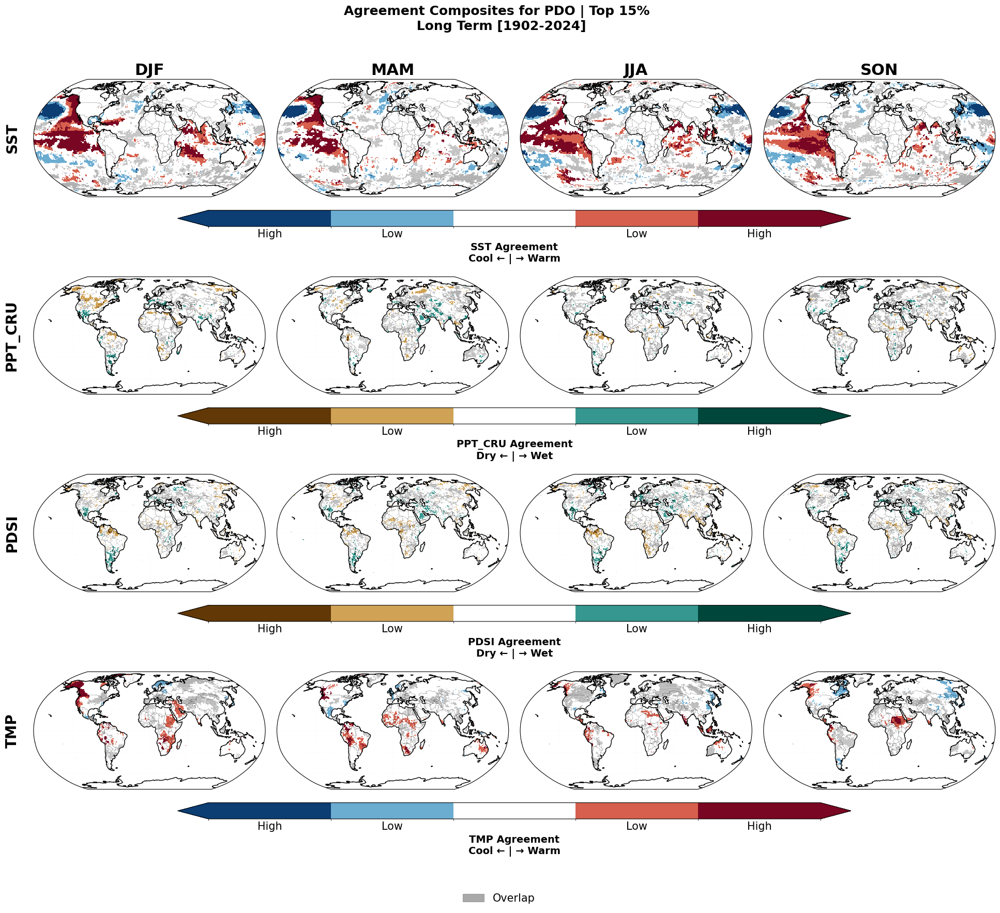

In [53]:
idx_ALL_AGR_TOP_LT = utils_agreement.plot_index_agreement_by_season_LT(
    sst_seasonal_indices_LT  = IDX_LT_dt.groupby('time.season'),
    SST_Anom_1903_2023       = SST_LT_dt.groupby('time.season'),
    PPT_Anom_1903_2023       = PPT_LT_dt.groupby('time.season'),
    PDSI_Anom_1903_2023      = PDSI_LT_dt.groupby('time.season'),
    TMP_Anom_1903_2023       = TMP_LT_dt.groupby('time.season'),

    # Phase
    phase         = "top",               # "top" = El Niño
    phase_title = f"{INDEX_NAME} | Top 15% \n Long Term [1902-2024]",

    # Seasons to show (can be a subset)
    seasons       = ("DJF", "MAM", "JJA", "SON"),

    # Index year selection
    pct           = 0.15,                # top/bottom 15%
    max_n         = 18,                  # cap on number of years selected

    # Agreement threshold
    threshold=3,          # min years to show signal in colorbar
    disagreement_thresh=3,  # min years on BOTH sides to flag disagreement
    disagree_color="#A9A9A9",  # color for both_disagree overlay
    thr_white=3,
    sst_breaks=7,
    ppt_breaks=7,
    pdsi_breaks=7,
    tmp_breaks=7,
    vmax_sst=18,
    vmax_ppt=18,
    vmax_pdsi=18,
    vmax_tmp=18,

    # Colormaps per variable
    sst_cmap_name  = "RdBu_r",          # warm/cool diverging
    ppt_cmap_name  = "BrBG",            # wet/dry diverging
    pdsi_cmap_name = "BrBG",            # wet/dry diverging
    tmp_cmap_name  = "RdBu_r",          # warm/cool diverging
)

idx_ALL_AGR_TOP_LT.savefig(f"../figures/{INDEX_NAME}/{INDEX_NAME}_ALL_AGR_TOP_LT.png", dpi=300, bbox_inches="tight")

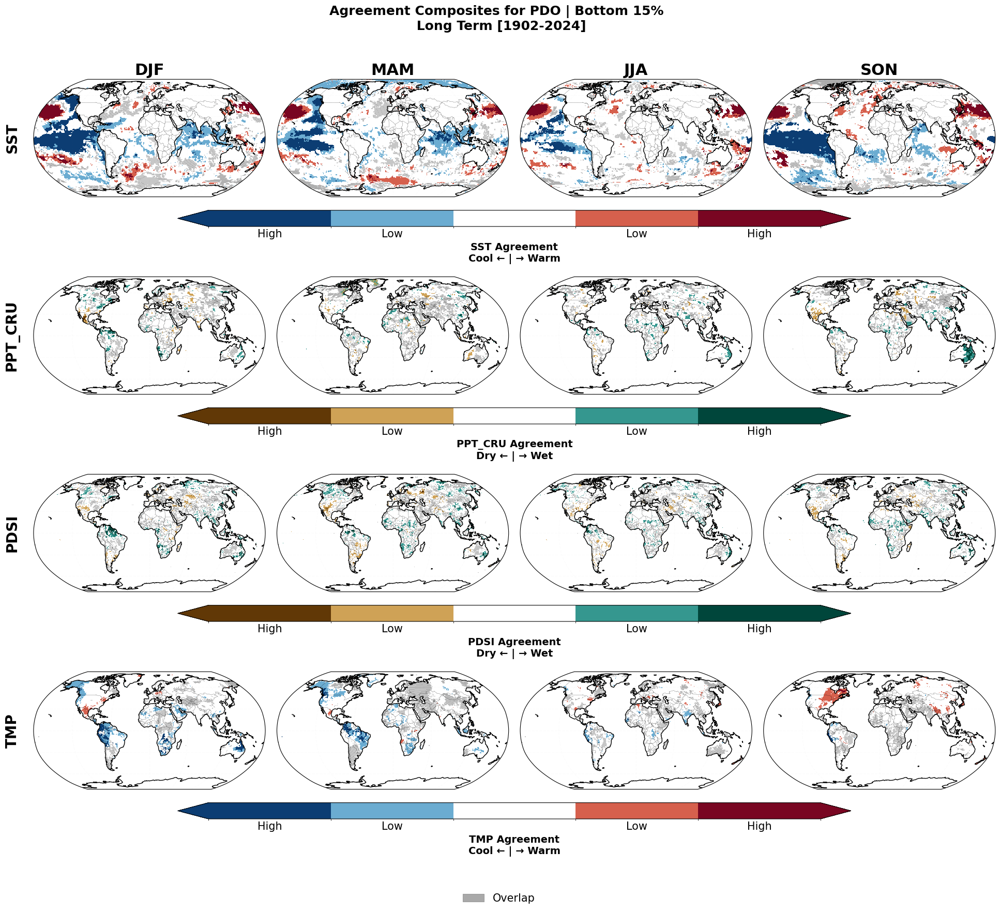

In [54]:
idx_ALL_AGR_BOT_LT = utils_agreement.plot_index_agreement_by_season_LT(
    sst_seasonal_indices_LT  = IDX_LT_dt.groupby('time.season'),
    SST_Anom_1903_2023       = SST_LT_dt.groupby('time.season'),
    PPT_Anom_1903_2023       = PPT_LT_dt.groupby('time.season'),
    PDSI_Anom_1903_2023      = PDSI_LT_dt.groupby('time.season'),
    TMP_Anom_1903_2023       = TMP_LT_dt.groupby('time.season'),

    # Phase
    phase         = "bottom",               # "top" = El Niño
    phase_title = f"{INDEX_NAME} | Bottom 15% \n Long Term [1902-2024]",

    # Seasons to show (can be a subset)
    seasons       = ("DJF", "MAM", "JJA", "SON"),

    # Index year selection
    pct           = 0.15,                # top/bottom 15%
    max_n         = 18,                  # cap on number of years selected

    # Agreement threshold
    threshold=3,          # min years to show signal in colorbar
    disagreement_thresh=3,  # min years on BOTH sides to flag disagreement
    disagree_color="#A9A9A9",  # color for both_disagree overlay
    thr_white=3,
    sst_breaks=7,
    ppt_breaks=7,
    pdsi_breaks=7,
    tmp_breaks=7,
    vmax_sst=18,
    vmax_ppt=18,
    vmax_pdsi=18,
    vmax_tmp=18,

    # Colormaps per variable
    sst_cmap_name  = "RdBu_r",          # warm/cool diverging
    ppt_cmap_name  = "BrBG",            # wet/dry diverging
    pdsi_cmap_name = "BrBG",            # wet/dry diverging
    tmp_cmap_name  = "RdBu_r",          # warm/cool diverging
)

idx_ALL_AGR_BOT_LT.savefig(f"../figures/{INDEX_NAME}/{INDEX_NAME}_ALL_AGR_BOT_LT.png", dpi=300, bbox_inches="tight")

# Agreement Years

Saved ../figures/PDO/PDO_AGR_COMP_YEARS_ST.png
Saved ../csv_files/PDO/PDO_AGR_COMP_YEARS_ST.csv


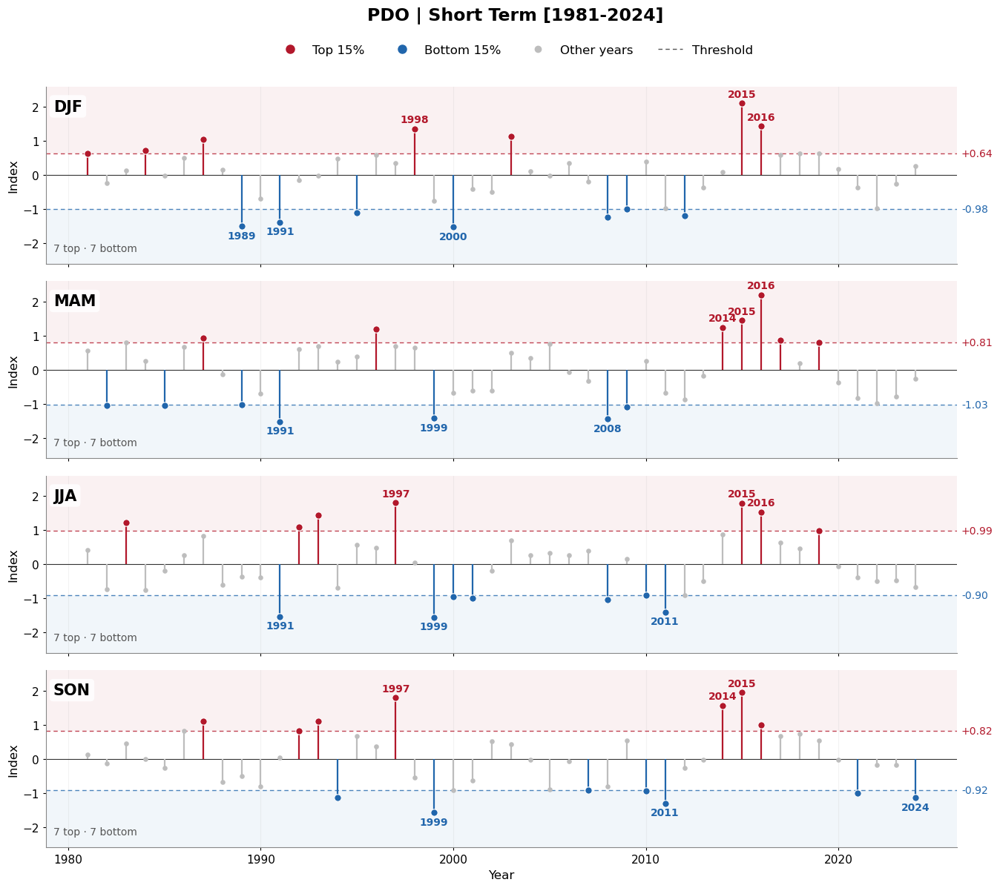

In [55]:
# Short term
idx_years_st = utils_agreement.plot_index_terciles_all_seasons(
    IDX_ST_dt, pct=0.15, max_n=7,
    title=f"{INDEX_NAME} | Short Term [1981-2024]",
    index_name=INDEX_NAME, period="ST",
    save_dir=f'../figures/{INDEX_NAME}/',
    csv_dir=f'../csv_files/{INDEX_NAME}/',
)

Saved ../figures/PDO/PDO_AGR_COMP_YEARS_LT.png
Saved ../csv_files/PDO/PDO_AGR_COMP_YEARS_LT.csv


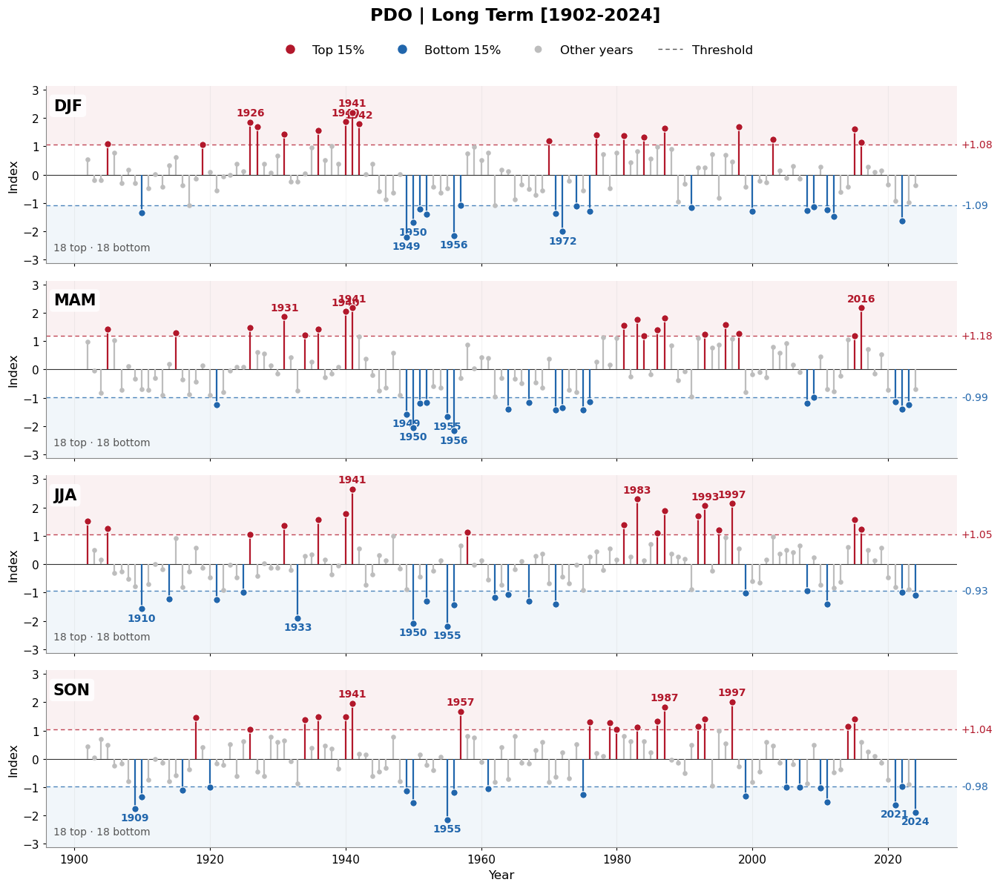

In [56]:
# Long term
idx_years_lt = utils_agreement.plot_index_terciles_all_seasons(
    IDX_LT_dt, pct=0.15, max_n=18,
    title=f"{INDEX_NAME} | Long Term [1902-2024]",
    index_name=INDEX_NAME, period="LT",
    save_dir=f'../figures/{INDEX_NAME}/',
    csv_dir=f'../csv_files/{INDEX_NAME}/',
    n_label=4,
)

# Plot from saved file

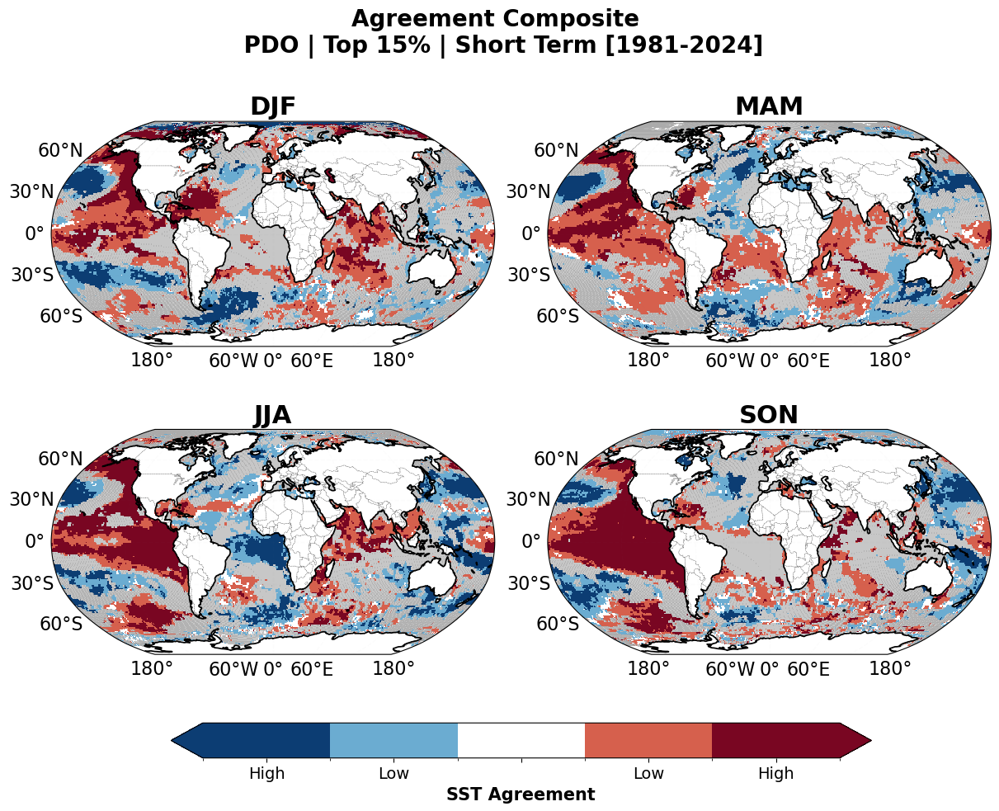

In [57]:
agr_nc= xr.open_dataset(f'../nc_files/{INDEX_NAME}/{INDEX_NAME}_SST_AGR_TOP_ST.nc', cache=False)

utils_agreement.plot_agreement_from_nc(
    agr_nc, index_name=INDEX_NAME, var_label="SST",
    cmap_name="RdBu_r",
    title=f"Agreement Composite \n {INDEX_NAME} | Top 15% | Short Term [1981-2024]",
)


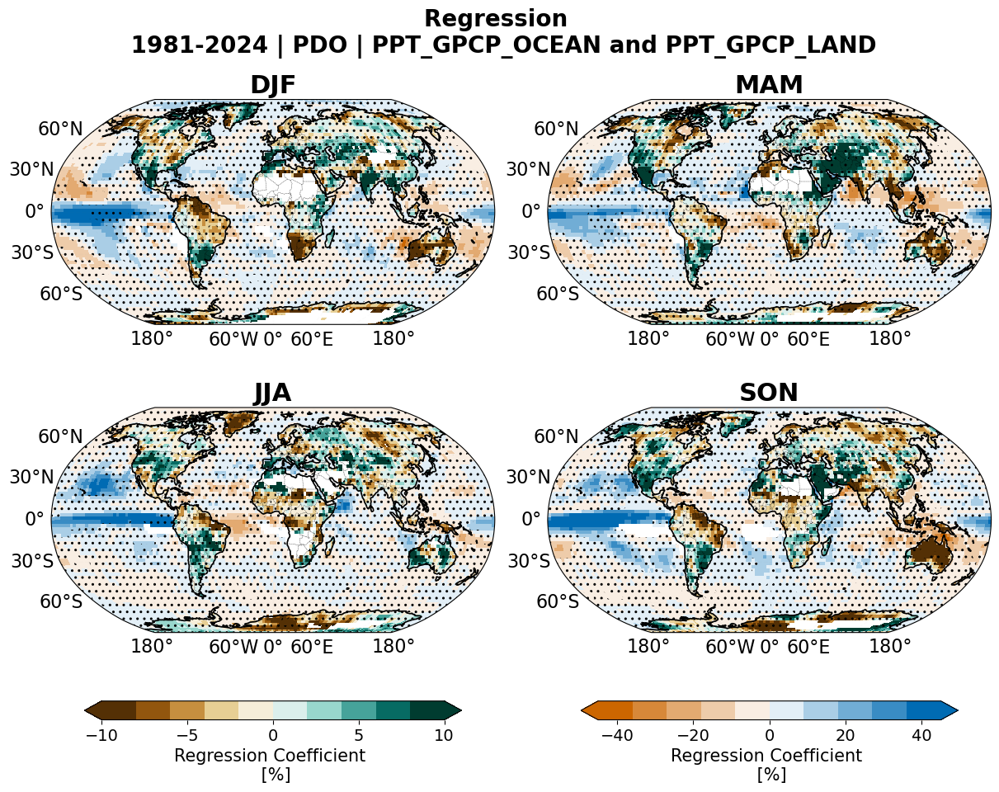

In [58]:
reg_nc = f'../nc_files/{INDEX_NAME}/{INDEX_NAME}_PPT_GPCP_REG_ST.nc'

utils_regression.plot_regression_from_nc(
    reg_nc,
    cmap1='BrBG', vlim1=10,
    cmap2=OrBu,   vlim2=45,
    coeff_label1='Regression Coefficient \n [%]',
    coeff_label2='Regression Coefficient \n [%]',
)

plt.show()

# BOTTOM